# MADT 7202 Mid-Term: Shared-Risk Supplier Pairs in Semiconductor 10-K Filings (final)

**Decision (hypothetical role):** a semiconductor equity analyst chooses which supplier pair joins the shared-risk watchlist.
**Network:** bipartite filer -> supplier (a filer names a supplier in a sentence labelled *supply*); supplier pairs are scored by the filers that name both, with **NPMI** as the primary weight (Jaccard is reported as a check).

**Files that must sit next to this notebook:** `labels_v3.csv` (context label for every supplier-mention sentence; assigned by Claude, see step 5).
**Files this notebook writes:** `filings_meta.csv`, `supplier_sentences.csv`, `decision_table.csv`, `page_figure.png` (the figure printed on the A4 page), `access_log.csv`, `precision_check.csv` (optional, 30 rows) and `core_pair_check.csv` (the evidence behind the recommendation, to check by hand).
For the prior-year re-run set `BACK = 0` in cell 1 and run again (files get the suffix `_back1`).

**Anyone can run this notebook with no other files.** `SOURCE = "embedded"` (default, cell 1) uses the labelled sentence table stored inside the notebook, needs no internet, and reproduces the reported numbers; step 10 confirms it. `SOURCE = "live"` re-downloads the pinned 10-Ks from SEC EDGAR (you must put your own contact details in `USER_AGENT`), re-extracts the sentences, and reports whether they match the embedded table.

Data minimisation: sentences that are biographies of named executives are dropped at extraction (step 4) and are not stored.

Run order: **Restart & Run All**. Nothing is typed in by hand except the filer list, the supplier dictionary (cell 1) and the labels file.

## 0. Legal basis and access discipline
- **Source:** filings that public companies file with the US SEC and that the SEC publishes on EDGAR. No login, no personal data, no scraping of a website that forbids it.
- **Access rules followed in code:** a declared `User-Agent` with real contact details, and a request rate far below the SEC's published ceiling of 10 requests per second (`REQ_DELAY`). The notebook logs every request to `access_log.csv` and prints the peak rate as evidence.
- **Before you cite this in the report:** open the SEC pages "Accessing EDGAR Data" and the webmaster FAQ on sec.gov, confirm the current fair-access wording, and put the URL you read in the report. I could not open those pages myself, so the rate limit above is from my understanding, not a quote.

## 1. Configuration (edit here)

In [20]:
import os, re, time, math, itertools, collections
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# SEC asks for a real contact in the User-Agent. Replace before running.
USER_AGENT = "Your Name your.email@example.com"
HEADERS = {"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"}
BACK = 0            # 0 = latest 10-K; 1 = previous year (robustness re-run on the same filers)
SOURCE = "embedded"  # "embedded": use the sentence table stored in this notebook (offline; identical results for everyone)
                     # "live": re-download the pinned 10-Ks from SEC EDGAR, re-extract the sentences, and compare with the embedded copy
SUFFIX = "" if BACK == 0 else f"_back{BACK}"
REQ_DELAY = 0.25          # seconds between requests (about 4 req/s; SEC states a ceiling of 10 req/s)
OUT_DIR = "sec_filings"
os.makedirs(OUT_DIR, exist_ok=True)

REQ_LOG, _last = [], [0.0]
def polite_get(url, timeout=60):
    """One GET with a declared User-Agent, a minimum gap between requests, and a log line for the evidence file."""
    wait = REQ_DELAY - (time.monotonic() - _last[0])
    if wait > 0:
        time.sleep(wait)
    r = requests.get(url, headers=HEADERS, timeout=timeout)
    _last[0] = time.monotonic()
    REQ_LOG.append(dict(t=time.time(), url=url, status=r.status_code))
    r.raise_for_status()
    return r

# Filers (tickers are resolved to CIKs from SEC's own ticker file, no CIKs typed by hand)
FILERS = {
    "NVDA": "NVIDIA", "AMD": "AMD", "AVGO": "Broadcom", "MRVL": "Marvell",
    "QCOM": "Qualcomm", "INTC": "Intel", "MU": "Micron",
    "MSFT": "Microsoft", "GOOGL": "Alphabet", "AMZN": "Amazon", "META": "Meta",
    "SMCI": "Supermicro", "DELL": "Dell",
    # Added to raise the number of filers that name suppliers (mostly fabless / OSAT-dependent chip companies).
    # Unverified guess: check "filers naming no dictionary supplier" after running and drop any that add nothing.
    "ADI": "Analog Devices", "MCHP": "Microchip", "ON": "onsemi", "SWKS": "Skyworks", "QRVO": "Qorvo",
    "LSCC": "Lattice", "SLAB": "Silicon Labs", "SYNA": "Synaptics", "CRUS": "Cirrus Logic",
    "AMBA": "Ambarella", "CRDO": "Credo", "ALAB": "Astera Labs", "MPWR": "Monolithic Power", "ANET": "Arista",
}

# Supplier dictionary: named entities only (no generic words like "foundry").
# Patterns are case-sensitive on purpose. Edit freely; this is a modelling choice to state in the report.
SUPPLIERS = {
    "TSMC":           r"\bTSMC\b|Taiwan Semiconductor Manufacturing",
    "Samsung":        r"\bSamsung\b",
    "SK Hynix":       r"\bSK\s?[Hh]ynix\b",
    "Micron":         r"\bMicron\b",
    "ASML":           r"\bASML\b",
    "Amkor":          r"\bAmkor\b",
    "ASE":            r"\bASE Technology\b|\bASE Group\b|Advanced Semiconductor Engineering",
    "GlobalFoundries":r"\bGlobalFoundries\b|\bGLOBALFOUNDRIES\b",
    "UMC":            r"United Microelectronics|\bUMC\b",
    "Foxconn":        r"\bFoxconn\b|\bHon Hai\b",
    "Quanta":         r"\bQuanta\b",
    "Wistron":        r"\bWistron\b",
    "Wiwynn":         r"\bWiwynn\b",
    "Jabil":          r"\bJabil\b",
    # Added with the extra filers: foundries and OSAT providers they commonly name
    "SMIC":           r"\bSMIC\b|Semiconductor Manufacturing International",
    "Tower":          r"Tower Semiconductor",
    "VIS":            r"Vanguard International Semiconductor",
    "SPIL":           r"\bSPIL\b|Siliconware Precision",
    "JCET":           r"\bJCET\b|Jiangsu Changjiang",
    "Powertech":      r"Powertech Technology",
    "UTAC":           r"\bUTAC\b",
}
SUP_RX = {k: re.compile(v) for k, v in SUPPLIERS.items()}

# A filer's own name must not count as its supplier (seed exclusion).
SELF_EXCLUDE = {"MU": ["Micron"]}

## 1b. Pinned filings and embedded labels
Filings are pinned to the exact 10-K documents used in the report (21 filers with supplier mentions, both years); the other 6 filers named no listed supplier and are fetched as the latest 10-K with a warning.
The context labels are embedded below and written to `labels_v3.csv` if that file is not next to the notebook.

In [21]:
import io, json, gzip, base64, hashlib

PINNED = json.loads(r"""{
 "0": {
  "ADI": {
   "url": "https://www.sec.gov/Archives/edgar/data/6281/000000628125000153/adi-20251101.htm",
   "accession": "0000006281-25-000153",
   "report_date": "2025-11-01"
  },
  "ALAB": {
   "url": "https://www.sec.gov/Archives/edgar/data/1736297/000173629726000010/alab-20251231.htm",
   "accession": "0001736297-26-000010",
   "report_date": "2025-12-31"
  },
  "AMBA": {
   "url": "https://www.sec.gov/Archives/edgar/data/1280263/000119312526119321/amba-20260131.htm",
   "accession": "0001193125-26-119321",
   "report_date": "2026-01-31"
  },
  "AMD": {
   "url": "https://www.sec.gov/Archives/edgar/data/2488/000000248826000018/amd-20251227.htm",
   "accession": "0000002488-26-000018",
   "report_date": "2025-12-27"
  },
  "ANET": {
   "url": "https://www.sec.gov/Archives/edgar/data/1596532/000159653226000013/anet-20251231.htm",
   "accession": "0001596532-26-000013",
   "report_date": "2025-12-31"
  },
  "AVGO": {
   "url": "https://www.sec.gov/Archives/edgar/data/1730168/000173016825000121/avgo-20251102.htm",
   "accession": "0001730168-25-000121",
   "report_date": "2025-11-02"
  },
  "CRDO": {
   "url": "https://www.sec.gov/Archives/edgar/data/1807794/000162828026043303/crdo-20260502.htm",
   "accession": "0001628280-26-043303",
   "report_date": "2026-05-02"
  },
  "CRUS": {
   "url": "https://www.sec.gov/Archives/edgar/data/772406/000077240626000018/crus-20260328.htm",
   "accession": "0000772406-26-000018",
   "report_date": "2026-03-28"
  },
  "INTC": {
   "url": "https://www.sec.gov/Archives/edgar/data/50863/000005086326000011/intc-20251227.htm",
   "accession": "0000050863-26-000011",
   "report_date": "2025-12-27"
  },
  "LSCC": {
   "url": "https://www.sec.gov/Archives/edgar/data/855658/000143774926004100/lscc20260103_10k.htm",
   "accession": "0001437749-26-004100",
   "report_date": "2026-01-03"
  },
  "MCHP": {
   "url": "https://www.sec.gov/Archives/edgar/data/827054/000082705426000016/mchp-20260331.htm",
   "accession": "0000827054-26-000016",
   "report_date": "2026-03-31"
  },
  "MRVL": {
   "url": "https://www.sec.gov/Archives/edgar/data/1835632/000183563226000011/mrvl-20260131.htm",
   "accession": "0001835632-26-000011",
   "report_date": "2026-01-31"
  },
  "MU": {
   "url": "https://www.sec.gov/Archives/edgar/data/723125/000072312525000028/mu-20250828.htm",
   "accession": "0000723125-25-000028",
   "report_date": "2025-08-28"
  },
  "NVDA": {
   "url": "https://www.sec.gov/Archives/edgar/data/1045810/000104581026000021/nvda-20260125.htm",
   "accession": "0001045810-26-000021",
   "report_date": "2026-01-25"
  },
  "ON": {
   "url": "https://www.sec.gov/Archives/edgar/data/1097864/000109786426000006/on-20251231.htm",
   "accession": "0001097864-26-000006",
   "report_date": "2025-12-31"
  },
  "QCOM": {
   "url": "https://www.sec.gov/Archives/edgar/data/804328/000080432825000085/qcom-20250928.htm",
   "accession": "0000804328-25-000085",
   "report_date": "2025-09-28"
  },
  "QRVO": {
   "url": "https://www.sec.gov/Archives/edgar/data/1604778/000162828026032873/rfmd-20260328.htm",
   "accession": "0001628280-26-032873",
   "report_date": "2026-03-28"
  },
  "SLAB": {
   "url": "https://www.sec.gov/Archives/edgar/data/1038074/000103807426000005/slab-20260103.htm",
   "accession": "0001038074-26-000005",
   "report_date": "2026-01-03"
  },
  "SMCI": {
   "url": "https://www.sec.gov/Archives/edgar/data/1375365/000137536526000022/smci-20260630.htm",
   "accession": "0001375365-26-000022",
   "report_date": "2026-06-30"
  },
  "SWKS": {
   "url": "https://www.sec.gov/Archives/edgar/data/4127/000000412725000085/swks-20251003.htm",
   "accession": "0000004127-25-000085",
   "report_date": "2025-10-03"
  },
  "SYNA": {
   "url": "https://www.sec.gov/Archives/edgar/data/817720/000081772026000055/syna-20260627.htm",
   "accession": "0000817720-26-000055",
   "report_date": "2026-06-27"
  }
 },
 "1": {
  "ADI": {
   "url": "https://www.sec.gov/Archives/edgar/data/6281/000000628124000204/adi-20241102.htm",
   "accession": "0000006281-24-000204",
   "report_date": "2024-11-02"
  },
  "ALAB": {
   "url": "https://www.sec.gov/Archives/edgar/data/1736297/000173629725000003/alab-20241231.htm",
   "accession": "0001736297-25-000003",
   "report_date": "2024-12-31"
  },
  "AMBA": {
   "url": "https://www.sec.gov/Archives/edgar/data/1280263/000095017025046499/amba-20250131.htm",
   "accession": "0000950170-25-046499",
   "report_date": "2025-01-31"
  },
  "AMD": {
   "url": "https://www.sec.gov/Archives/edgar/data/2488/000000248825000012/amd-20241228.htm",
   "accession": "0000002488-25-000012",
   "report_date": "2024-12-28"
  },
  "ANET": {
   "url": "https://www.sec.gov/Archives/edgar/data/1596532/000159653225000028/anet-20241231.htm",
   "accession": "0001596532-25-000028",
   "report_date": "2024-12-31"
  },
  "AVGO": {
   "url": "https://www.sec.gov/Archives/edgar/data/1730168/000173016824000139/avgo-20241103.htm",
   "accession": "0001730168-24-000139",
   "report_date": "2024-11-03"
  },
  "CRDO": {
   "url": "https://www.sec.gov/Archives/edgar/data/1807794/000162828025033813/crdo-20250503.htm",
   "accession": "0001628280-25-033813",
   "report_date": "2025-05-03"
  },
  "CRUS": {
   "url": "https://www.sec.gov/Archives/edgar/data/772406/000077240625000014/crus-20250329.htm",
   "accession": "0000772406-25-000014",
   "report_date": "2025-03-29"
  },
  "INTC": {
   "url": "https://www.sec.gov/Archives/edgar/data/50863/000005086325000009/intc-20241228.htm",
   "accession": "0000050863-25-000009",
   "report_date": "2024-12-28"
  },
  "LSCC": {
   "url": "https://www.sec.gov/Archives/edgar/data/855658/000143774925003987/lscc20241228_10k.htm",
   "accession": "0001437749-25-003987",
   "report_date": "2024-12-28"
  },
  "MCHP": {
   "url": "https://www.sec.gov/Archives/edgar/data/827054/000082705425000077/mchp-20250331.htm",
   "accession": "0000827054-25-000077",
   "report_date": "2025-03-31"
  },
  "MRVL": {
   "url": "https://www.sec.gov/Archives/edgar/data/1835632/000183563225000057/mrvl-20250201.htm",
   "accession": "0001835632-25-000057",
   "report_date": "2025-02-01"
  },
  "MU": {
   "url": "https://www.sec.gov/Archives/edgar/data/723125/000072312524000027/mu-20240829.htm",
   "accession": "0000723125-24-000027",
   "report_date": "2024-08-29"
  },
  "NVDA": {
   "url": "https://www.sec.gov/Archives/edgar/data/1045810/000104581025000023/nvda-20250126.htm",
   "accession": "0001045810-25-000023",
   "report_date": "2025-01-26"
  },
  "ON": {
   "url": "https://www.sec.gov/Archives/edgar/data/1097864/000162828025004557/on-20241231.htm",
   "accession": "0001628280-25-004557",
   "report_date": "2024-12-31"
  },
  "QCOM": {
   "url": "https://www.sec.gov/Archives/edgar/data/804328/000080432824000075/qcom-20240929.htm",
   "accession": "0000804328-24-000075",
   "report_date": "2024-09-29"
  },
  "QRVO": {
   "url": "https://www.sec.gov/Archives/edgar/data/1604778/000160477825000041/rfmd-20250329.htm",
   "accession": "0001604778-25-000041",
   "report_date": "2025-03-29"
  },
  "SLAB": {
   "url": "https://www.sec.gov/Archives/edgar/data/1038074/000103807425000003/slab-20241228.htm",
   "accession": "0001038074-25-000003",
   "report_date": "2024-12-28"
  },
  "SMCI": {
   "url": "https://www.sec.gov/Archives/edgar/data/1375365/000137536525000027/smci-20250630.htm",
   "accession": "0001375365-25-000027",
   "report_date": "2025-06-30"
  },
  "SWKS": {
   "url": "https://www.sec.gov/Archives/edgar/data/4127/000000412724000131/swks-20240927.htm",
   "accession": "0000004127-24-000131",
   "report_date": "2024-09-27"
  },
  "SYNA": {
   "url": "https://www.sec.gov/Archives/edgar/data/817720/000081772025000073/syna-20250628.htm",
   "accession": "0000817720-25-000073",
   "report_date": "2025-06-28"
  }
 }
}""")

LABELS_SHA256 = "8af9626b95f5306bfa33dfddee343d2eb1136d584fc6c67f5c8c0a0fc24669ee"
SENT_SHA256 = "ccef1cab427f7f23f7c191ba59aa9863ee7412bb75408b0182abea23d7080b07"
SENT_B64 = "..."
EMBEDDED_SENTENCES = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(SENT_B64))))
LABELS_B64 = "H4sIAAJYymoC/+09yVIkR7J3fUUaNmOAWcL0otbMqE+Ihm6kpkENtEbHqMyoqhiyMkq5QNec9AvP3ruM2bzL+zR9yfMl1swsKHqlGw5agMxIdw8P392jUdm5rNK6nc8LBf/TyLdNWoiRLNJSN/KbV2+e7aSnJ4e76dovMmkbVah/yWSs2zKvlKzTpG6zaSLq5FSoS1EmJ3KmMl3mbdboKjkUZTsWWdNWqpwku3o2F+UiealmqpF5msATtHQiyjw5EbO6haf2Cpk1lS5VVsMb22nyssm36VnzRJo0OplXGr4hE91WSR1981KMZVVvrzFOi5RRsO9+PVjM2yqbilomMznT1SIZV3qWnPyUvFiU6m1yUGbwuUOVAQzJqcympS70ZJGaPwSg9r5hlvioH+F3Puon9vVbICd/Q5YTMZHJpWqmiSpzOZfwr7KBbR/BM00lkOY1rWZ/TmZu12EjHIO8ADBeCJUcVzJTtYKfDmDL6gYAD7b5F1Xj5sOvqrmuRAPPMaz7YgRMJBvafFmNdTWDVWHrRwB30si6QRbDJ+ciOxcT/EmPiT/GqhSF4Zimxxnmi3cEW3cO/vj9/xIru2p8dyqq/FJUklat9bihH8Z47vSuWy9ppqJJ8C9tLXMgEpy+6oKWqBIAT+Y5/RrgFm2jZ3qkChQT+EMJP7Y1ECybAm41YzoRMwQ+lxcqC+XJzmwEXykKYRl25/BZmvxQaZFneoa/bEDSJj+3ooCfZ/iQISJKltcSPgCrxMKkQ2QnTwD0jGQTSDS7+Y2skI6NhIcAulpNSoQzogUSp5lKVSX6svS/JgICVWKETmVtkXmKj6yl+E3ZKGCp9OzVydnrve+TUVsUsOt0kkVSAHvg1rx6c/DsYGe9pq/7t+qnyVSKHMECjYN7AcAklb78BmnVUz03l9DJBi6yafG0GCI3A1QsaOmPyHcvjkGQ7x8/3yH8RS7mjbqQMcHwL89fHv2w83L/6OzVs9cHeydEEM+kCPnzQo9Ese90zBeJBJN/J88VfkoUeG4vAzxI752VBCEJaTnMqsnGGUJ/rYZcgh8idbBbW+YgQQK/hocmlZjNxKiQCagFldkT2EHDyYsvHpOzr2I/3KkG2bhIULN/4AMBlAkPxQxJAU8AJDX8SLx/fBYchib5a1IKEO0SJGayUc42UZzWM1gHfi51bgX9pYF5XqmZqBRD/27C4K7g7jZbFLX+yKyKjIlab0IaNMlUlbUKkNw4gCXeW3p8wTicfeF7wEy0j+bZWzGbFzJN1JgQSFRNhgMtAQZbYMl29eJqR2HWY396Ehco5SUYrSD6/DtoO7bjscoUmti/taIEqwYtMARFghWUgb0MZ6sCxAA0sOoU/E63RQ62KihlAQDDuVNgpYkcTVCw38djoC0eLvzmqK3RzlyBIHA+0aSdV7IGWOB4jnWGL09oHcIMESn0JUBjEFhKE101Y10oTRIKvvXH7/+uE/NcuDvWvUAvlp/0Tz1NqhY2pRYKyAfbXgWQH9x4967fps+7F4e6khreSp2gNASBIwaIWh4iQvjYQxgGMAiT7W4NZDTcjO8kkMiiaSo1asF5coQJ2HHo1N9CuJhgp/BBCQ8D67JMcOGYuagalbWFqABaYpPLqQIHJOCOesmBTJMZbHIyko6lwMEta7KX8CfYWIQ3D9bCE2J4FjwlE2JQ5tirMqukQC+RqJDUIDgRwpg06E1mmZw39NGFkkXOr+eyAEqRmp4hf4qkUTPcA/h8KauQLm+eH3nCwN//qSvVLJxDDLK22ZKlhSMGX8NWkKSu8UDptqnhHcQSMJZvjRcYEBiwKlryud7F+vjj9/+wSPjfzWEEfiHHGpBWVb6Fm7lIdg+ZMURCTigcUjidPSxtdIBohwGCALMIamLfHbuXMfR75QROqUTYrdttgkFBBCl5Xul2DmvMzjGA14kssaoDLQlvUQShFwFB/nB6r0MEWvOeCid7d54GYRDyLtOBxcIzlidjVWcgjhZSVMmjB4+egHcxB3n6VqH2BUz//uTPiD3qBCNeA7mfJ6MFEQbJB4aM9X74D/idwW8D/UcgiuUFB9tZhlbyt1ZVcgbWQg0/GMMJzQApME42bgsyhIxj5cygRjc+OIl/zMRcZLBp20NYvwB7i9QvKTIywMcYGM0EKsvQyCEN7GJ44e7WYLVYjghCZ6kJ4qIFk021Bg6DdUbSYpazScU2DXtuyFxo+1uQwy8b64iioPAyZSbAvixA7pewiFVmxjpoazQk6ikQCE04MNo95a1pt3MhJnq9djHap8l6AP46fIWwh9UYBHrPwRHaj/61kLYHoFFNMMTQdypgK4WqMX6KxJmJhXM6WjIr6a+pCXkCRTJjIAaWp2OR0HA5fP3mpUtcwIcPYWVg38dsvewuRvA40FTCIQR6YUxcWM7ZnQIBkxGq/JyerkVB+7kksWGNbROs1kkmq0YAGtJatPD/vCiFaRvytCioTYFa9+ocWSIUL7XMWhIvlarPaWlaBrYoQ8bAc6lKMuoIdvj/SgAmLdOFSQGshrDgl0vBcSi3LtCLdjJ1KCOTGDQtWE/Z5LfLgU3K8myq5uGW85+/+Xn36DAwjDj6sDDWzCII/1u780IAmwN35mqi4KAiHwig7V9m6q3Mt5Aa+MvX+4TB8eGgs8pH70aRWg7KpIMeMrlVFANKXBAoYC1C0YUZvmosjW10RA4d4xhnPvsKz+OOemcVFddXYddqLlJvpzunJ8C48+Od3R7caM18cVA7ngJ5ZdQua9wKVFLZorOGSZqdOQUQ7J7iqv9QQs9UIkXGPl+FIjV5+ODPqBJmugrUUVnrQuXEWXZZgMNK8S4ku0aUmdfBx5sguTjHBuK7zOvAU6+TjXEY41gK6SYGjmSh50Euq8/ygZvIHiU8vGDn3yiJOYg7GyBjFfIXTKy1VcUxFfMnVM5OKrOxoqogduWwt5DmsgYJOwJQQEEJRruH7TLp54i3x3QAqliLgNFABiGFIzGEhvZlaRKiQGPSFqxfBfqym+7c+0TkC2V4LU0OZa7EqTyH/6M9WQCyry4U/BL++4/jmIOBkD/r6kKnPg95cr641NU5/OUUtq0GdkUFwkYW7tfZq4OTI+TUgcyhzRVmwM6gkc8lAy982AHVCBw2MZFPEyxWQVUC9CByDFPhm4NXp7veXiAFiWzaUEDkkown+XYOYixNNPnq4KFTeQYopHHT8bQxoBAY8VcFLVLc6kvpGDPKuHLEaiQXQElOAycP/8YJO5TMOciEC0FRFnwy9Y9sHQeH3KMWGLgmDqhLyZxZSRlkhjeQy4kb8PPWdQhju8gfFyY5D8R/VM5gX5opRmrnU5ZwJVB+ayJL44mYGEtNkrCCzWukCdIAuWwIBGsNFAgHQBDECVCaWQK+EMWRYHVpYngZW6expOUoMTJIvR2y0FxiVFNzpCcAnXHBb/XDkUQ+y7j3FHxXCvLZCpWjXxUXKTi/vyVzkHkxLL242wLdBj49LNqmmmJpdhEHIC4cH020fjM0rG1ebKZBmriAH524WOz0GIC8M34Azi14UBnKfAp8WkFOekKhT1qdy2a7v1wv13dEopcP8L6x5wIvyEnj7osuPHtyeODI4ZNvFN1H6xps9Zb94F4IcwhdCgrfMpicdAaKowuOsQH42NS6zpfSROhxf5yIJ5/W6uoBsbzoMIj1eUPPWjT2mKM1ci79u5GfzRyJjGXt7gZLghJKmZBb5iIRDVAF4xLEeA0oKnx6TNU5NaiY4KimwK9T8LML8rOt+w9iILcRHi/qeatyjUqjNVVy7PDit1CfAQF0O5liToPZGMhTG9EUILPEqY40CatDcjyNyGGHX3pJx9AO0Tx2VSy5kLJMMtLnZTsDf5lUPZtWtKjx0F3WINZzZ4ZHwIL9lrNdZQnfxLMtAr2f6aIQI5u5pLOLTEtylBWxSB4+wgSS5c45+J+UkSQPGpBHs4wzhsTGf/z+Xyg8/PMuOcbeN8A/AXKU/M7Z9sn21ohSBjH7OcYCNgTDihz5lAEMYklMew7djAAhEnSA8l+da22NpX9qMHAdUAY5FNMe6Q1rBIGw32S3OwNBihYKMxTwEoGG7AQvDBigRPqdk8OXbD2hnZUBcp3TieoS/HiFMYZ2jnEhXcgtzkIgiBfI00EdGUGIMnrv7E2kGxuti37AD7/vi/ZcdAsZLFIuQ/KGKuMcCH6Vuh3VDaYISYwAo6PkYW+BWBQzpwXq/RZ+veiAbk3/ClcCgsKvZgqVeRFEUshWxLhTmVmVivUZ8FI5YcvCa72oMMtlUI0o4WCKqk21h3FAmbiwzIR9bt6wQetw7VCzYd0JILp84BKb1pX94bEPi5edig2iZlRs1g9XW+coVvwIBAje0mNsE4WBcliDc9w2SRQyRCkEawZAIlcTN6/X5PZZAbQWq/e7TANTx0fuyBw8wtbUnLPQXFCasMbkpaqnHauA3FXKSrhD5L+98HHkTgg1wjSIb9ckLsYYJ0X3vKxl5NuRILqURbHl4JF5tFvhdgReZzfuFFsqV5l992Tpm4f3JOlbp6dTWVMORCxqa41iLU38US64WUGUpKzgSzlWtlSaPRXn1A1WKJAB1diUl8DSaSRyG6WLrnAP0wR9TtjIwEX09txYksHjwmOE5lQWc+krIUjmBWUgWBDjJdywEFsuw5AUIZX324qMnCjlhWUeXJtEkcepmkypFCJSmqFRSRUTsTGJbqwuLhh883E2SLvGhondkMkaOLK6DMpUQP0Cf9tP2bqg1NvxV1rGHbPeyGwHqTW0t2YCvkFAXmu1r52ysYHVHmCDNWQ3KKTMgvsAqnZu3WbKQHHu5UoisHezWAEj5BfJEUYUAsBBbdGwsZOret423sO5pOybi7yNYDNKW6qDmBXoejsVig6C/aWjD9t/lBfFA8UIgJWmCvsLDAaSCOPcKHc+mHyglzyVBMufD5xZhLtGyK4KlubTCe8XVElDUbkQczwpjE2hztGYsKwmQiOTRUcyUeyrYbSpnutzaaEDVCnajt+0pqOPKS6pV7Le77DVdxSWzVkmZVCjWOdIZnjafKvQcmvog0U5rwtoYskEiZ9SJ4UGAx9oP/MNS2SF+747NbZeiOcmyklKs+twBkRcH+j0ESoTcQEOI76HCWGS4PA11kCYQY64tJspXlILCizQzoxF2JALXjc2RztHF7I2ktQG9YDjMiNL9dDGDZPJCczZEvOWiIgUDEVoqDPD/GvtCXulm081AFM4E7jzOnX1eeDIgKBva4uyLxYEOeAiItcqhyUgBXifcowFm7vkZQAUOdecXGcCsjqWsZ/IEVhRbUW/ZW4tpcyNbxltwx+//3eQB9KlLU0MexDjDbImx5cAK3v4UT0xOd0vdEEmxavtNy4AgVUyVPE7rsSEpGcNsrDBPV/H59afhiqGqhPoKePAYuibGryCD2/gfzbxCQ82raELL2uRUMPxAjpWRgCAFCv0wsSvqQ6VJM23NofyOO1IIlACVJhhDIaIzMNS14aSB47jSWC2xPHnKwJdnG2ogNGLAmWNVHTs5Fsw6Go4PMViqX6Ogi4u8uA9y9AstLE4/GtLAW7Y5aGFu6hFPcGwJVwx/Grn1TPbtRtEMmIti991mgeEJyw1paWs3sQNi3LIjEmha3saxqoCOs6pSdjUhVG2RJiWlzJ5JjNJpt+jv6cYK3voWHUtV5SIYWE9ZpiH4QlqUhQVh11VlbLWJcxBiZK8lJmPOhL/Im65RSdlk6QoTIQP80htgwYC7Q8Gv9UFiQRK4qDZ5vpQTUssgEVGOLdnNk3BR0tMKil97M9iFYTmCR8OK9rgFWh7MGlsHQErogkcbPpNXetM0RsOmU66BSHAdIv/9kg2lxKsm9ZUJhgo/G7Y0GUI+bjh+ugk2KqnHoNC6/OaDCtSKC0ShTTRX1yOvbN1a8N5mO7PcTAV+3RNjm+RlGJm+qdLNCOMtEMCgehaFiO95ntcd/mhP+oY0PExf2H1lZesE4J708UwhID/vMfb1/ck3Xz1w7OolWtpZMF6SFGszsg5DvgDCKQbMANo3YMwpTFUwnll41TA79xa/ZPSb5Ww2jdCHJ5FeVGfx7/cBWts8g+A/ZAhPY1C4NyWF0Y2kBqhWL/j5ACtd+DLtXGuwNGzwyBkY/+Evfpgw1I9HOjQit2PX9TloowmIHSCuPbEw6KmPd4Y7M5jjMMqQHdbC4O/f/hg66d0SZ/8UzBgSCVkU5mdW7dRkH3kSl/BSywna4wlY/CVI8nAfr1Ifm1zMDKejnM/GmOl0RjREJ3IaaNadNoRmUwwxFOyleVS5ZXE2tGMm8XYyOWyNmsVok1Xe5+0qUmBwl+ohMKajvZvFKIEt8EAE1rQpvrQOxOmDDwqhVzvv7B+CyZ/7HwNkz/eGYkrO/mWzAy6b+6764RZ0u93x8lyVQvgHSeNSVwRjEER3i5aa1FY6l37A/PBhsNvh+H43H16d6M5b0lXXspteb2uvLbuwE1/crloeobw6Jcmf2l9Y/26hGU9VletelCaHCW15UUzXLC8YfPL7jr7zDT6efeUWjNtKH+gYjoFE59dKjTZC2PDNToNPBDrMdya9ps+mlb+4TEMXNkw0cexIjXunWRyboKkKHtaILhNitjLaCdMlslQ2x0WPOhcSuwEi908rE3CvPRWjUlGT/AY2V4RkVt8HaDYmuqWPHA1r6/qofv2FvbQLWuac10pH6tF7ob9cXaamCkzp6xX3KNt3SVlKo7RIIKHuguh1jAJalHGGdANsowc6FbphPXstYQleb0ryOA6vrj0AT+aAxdUkmwRdMr0hEtfosJgByrrTk9UpEvAgfRSW292eNQPKqIdo9Jh2C5iS2NM0MPl5Gk3ceXyrR2mcYUCEYhoi6x2uoiO7ginJtfqwauIwDdisWSD5yvZFOe5SfnNQsm6uSoj9pjQwvSBeetjbJXLfEQllev1ksFEF0IVthzFzffxx5+K0oM+AqtxEYt2DvBYLchJcPsNrv7Dv71Wo5Eu9/dOk40JgLgFBNoSFQLFU+COcYbYGyWSjZHIzreoFm5Oc8WMGbrYRC5yMCg7NphyuWA7mqo+m5L39UyU9e0k+fnxsGSFX/trWEj03SCpntrSQPjWQ2xms6bNQOOZqx9w+0hntd9NsurAvO3P17Dh7d7QRgFW6JTsVjJIEccpnqjQp/GtXdbRACjs9KtognPEqQSndaOoebcQaIlwf4z/NFB6p0YTx8zcYgNxhcLd9ENYe8trw+8p+I4UPLvnv/egnm3Es62ocVFe1IoqfYXRgEzjpCyVuW5f2fn6kb902xpQyOb8+L0Fycbz/c0bjFj9yNLsnv6fhf5n97z/2Wj/lffupLekeceXEsUzmql1+ZHt98CBqOgbMZMfzRtRyqfmoQfcR4y1hLnzzrtlpkOVm0+NzoZFHv495biCsuWVT57jjOCqmU8xwTDTOfiWbhE2Asxs3xzHn1MsncZxoMnBTTSXAgt+2QwHMwNrIWk0Luw9t3EvTG4WXWm7NoVv2PoPK1CnNOEjbKr+BIXPXK/Qjmr5W4vOxsoFzjYK6su8GwyB8NSEdYZ8/ekwqAReZ7gDT8vDEthCI+Vd4WjtNpx6BkYKy7EfP0r+jE3VnPiCT59Lh9jhSdBzJYLWFiBQhLwVpCY9huFFSbj88fv/BEMgADT4GH8DQPkBwyO7Yo4h7uQEfFhs3zmBLTQzdtmnfBi9Y+qmTaErWVDgq5H87uEA8H8fjFXhAlYm9vWlxu9Xgk3Da+i1o/kuYGp+vxmeqLD2c9X66WsLVNc27KObn6j2OwR9rFHeb7XzgYJ2qiB1hw+2p5QT3Siz13E9Naak5ggrF287rkK3wgLYp24UNp/NMeNL9dQSK3GGa60VjSNADNi9iUq1KRxCsRUDpPlyOAZoKTBw7IC9qRdJ1w6Im1HtUNRYtX1s7+7a6ZWA8/ELdXRYEW7SzbzpguA/AoWP2/iQt/FBd9qFfDtVI9VwzRROali4khjCkUrR3WViTrQM8OXnrQO+ppT1JlWxVK8ocSfgGHBCbnnh4ucu+P1seNMVHscHLzkcsXN6eJz8+KZeYbgiVywwF1oV+L1dwA/Zw6LzfMWOJwfLBv6bY6k/IXV+bUF+xNibzOdPv+7tblrrn79uaw97fV+d+cOM9d0dPc35DyLClzS5k2Utzte6bWO6GKj74RB9mkS1LqEs7E984RoAO8A56omgzUKWMamw8HR6c5GTiDPu7MfmsUwGA5VMc7HV//1aYHrbRfJi+KLYKe4mNz0TsTzswSitqKo0fhs9kyiqaIqBhylI/wpaelbpWaL33iVesPKHlqZXMNfF/+7IBZBAyzqTBq7DeXbg62y9CWomEFCFAGUfp6IYW6k8MLpelGVLBRbE9qGg54fD+Pf7XXprapFdzMGUc1FZusQmezzWqk7s9SO++COsuftEWL/ndSc9XIdRQM6pZG0H5nFxXRnMScCbTsua/cas0jWbBBYQEJ1g1Loyv4nUc12YLl6aUlvbGRaqxhEe/haCUBmHMyjM1UWo0czlRajLTaSiI1575fw8v8qN8EjNxwfXdG4gvsTP8/CCeX984TeHuy+Ojax8ZU/kMzkmyb3TgitSqX8xh+5kDcn5fa61+dVUbT5m13X/V/r/V892dsCPRAFpO1QKcRn7g49TG3wyI/YuFG8DiaaJ5tfMDU8qfPPBo7/SFT/kcdQ00S9qprBNssR5JiPbm2vKBKXpq8Zc65apsrz/9RAESrL7j8NTpr4buELD/hcuFAVMi1UnaMEAkS3tjAsU/Q04eCbxLNmYFk2C0ZclVUlgzTG2IOemL4aaljnmhisFeNL8FrygCceTmDl4bN+DiATbe+PYkAje3rXaYbPf7Xt2QhZGyyeXpSAHFZECPOXG3w1QyQkcGwyTWSnsGnydXU00oZAyTYqmQAtfHA0LDoVQAvYLO/SjBvy45Lix6pgaqPwr3jrEOZxBH0z8Mu5ql/1v0rCD91is0LTjmnX8QMJLd+OH0cr6fVt6bCUV1ffQUNxOO5W7jQIjo9YFN0jF29u5HyLC630vijh6FVTIBaYezV71NU8HJ8/X604zly5ac3sWG9TfJycazuHVaiLoNrvm2nf8xtGsVCyAol7UoVbUX3468ZjgbVtUjYXXbYGrUWUiX4gS/69SIPp/0DhPaVdJtCV3QWbqNNnDiE6NgO2rkaYK0+cCBQH8F9R0Adu0IZLTKbGFMVGwupbGURcGC5XBb7SeIJO+0KVcoD0NHhndM568lKXGutOXz0OkzVXt2HCI9auAjsaeuFd7p8/3dl7D/+hzqmMFA3Vagfn4vGpnM0Tm6Pj4KE1e6+wcvwK0KwpVUnnvRM4IAV/gCsST5D94OE/gQFYi+UXheASMt8H2af7PImV6w0YWGqv7JSjC1HbrnR5vvVTleZq8OXhzlAZVm0Mz/MV8jnOJeTyoG1Vvq66++fk1LOH27UqWGFqctS7VfrpFO2turNll19Y28cY5GofA81+orHRs7iay6wCkIzhvYQdEjertO8IUr4JYHZSXJ7smlflSNNhR4EMgq5dFra3BCgS8GXSPeQksbgZpbxaID92P4BiWvTVOfqRFrhrGhIEs+M/Dxw9K4J6/07+/e4L/xk9/Cz8nu4dHJ0tGxtJMK8xH1L4PdlwIcGtNIIyDZLVcOhOGyBXGGQ214mniMbLx/oYTizuTy3xoHOOzXHlHbX+A9aO/AWr7z7ZOjg6CnIC1EVXten0pgSDftsEAZGAgWmbg3kbCx5ntETI3MarXKDVyDXqAxcPvAItrwd/BgVL0OiPyyKFS93BJrTbssszjJ8QchlOePDH3pBKLXEsIOy2O4z2uTQhtERpCaMsNzVExNUPIwIFI83PM9uYktim4gqhh57XPkhG1XTk50tPoZlVZHwTbPcFGB3CwbekqfvyyID/7IulNPZE7XF18XUiVi+E4g8P+ga2atZO/wos9rwpbwiE7Otk5rfGU2ciLj37aRC1fXbFq2LaLmOuCpSqD38ATV2OFXsSlNmE+B6HfCyAHNyZ34qUIMf3Oagaaz82jkyzCPAk7GKrnCq+jqMCMUqxNAk4NSGVAeBhy3JMYms6Fqh3/QNW2RHB7aLl9xbMEzJUfdbyP0Yd8Vt29k+RYnNB9sB8uiiWPHVvt6yQBQlKXafITOG18N5yRzegEsBFN48dsX2PvHJmEwrAze7NASjqs5FaqCLK1QOpc8xG9SpDdaUKc3XNDKI0sGRBskoFIhkOBdV/oeBg4cTk2LA0lMGDOHSW2ijic3R5KghDr62XnoLQbVBJfHuwnL3d+8IXKLoxrLUOfbVrdRtweWDy8bfp9KgRhGQzo0DIdI7AZuG875nlzGWgMHsWHbi94RD175wFlhvqnOxgo4mvJSKNTiRHdrxtFtsxkSpwT+UE2VFcfgGDX7svH+MpAj3sUvM9wAFmQ6NsyBHNBrOvj+uwkc70QbnqY43DWFTjQdowEZ4TZSvHndPf12Uk8zUVQG7dkbooUxrIBM2nYpcEGJFk2Q3NkUrTmOglpa9et7immfv6Ncxm7SA0O2vma8fMdyHaWxSMTQDbuSWdk6K7Nqr+WmITwdVi/UIbshG0ATBcoyiwHdVwktLsjLGHRilYKRlSYQaQm6WbHZ4/DHIgNCeeRn0UNJe57GA/E26vwArcyB+Qsht91qWKU/alH21yXzP5N3zGijm5fK7F6ocpwOUrKdRuJKdxIjhvZAxE1+m0GkItiODh9sr9jv9SNWb9D0U0jlO2lJSOG46QbLrHuJ0Xja+ubfS9nkPVxwN1rurI6mGNLve9+NLzlyKrD7MyZ1uC9ksOvOX9H4H8H1z74b/cWH1utHCXfzWODX6YVtfmAF1rDFwp5X5+vkCziCdG9SKjwaRldYeh8JGplImJW4+Nsck489vGq6MqqICjCsc+BCy2WS2Zuu/jQG2bjgnx2ANlRoSZGfYbZqDBQ1BNrK8uevkRmTogLE7AWX43he8QJXJ0gg5ogA0tkb2UkhA1jO6iHwKW0rRr3sFA1Z8vs7QdAhHq8MNfYhRooBDY14A8k79k3BMulpPJ3FERcXJXZizt8VQAbKdE1FEs1GNZocw1Sicl3cl809uPIC0VOaJBsNS37ro/cXkCvcagJ3ulQf1L9B2//2MIbj/7GpeafQiGuxIY7hbn88dJfYku3lPr18IdkonVum3eIvm57AQ0KtNnplhldPhsNouolikMQ0w74g/Qz96LUPltNIp0OAp0CZkQMbw4NibL3yii8JZGSLlgUV2KpQGpnPVAD6rUXUKRWGpVywve5WDOb3e9CwRHJ6apQjGQOVb/c6Mxcu4HHy/gg5m9VxyPDDB+xIB8QCOHDBgCkiqF+TyKRpvitBQdD4sQBUhLXgr6H99nQdosrNKK7JbJusP0QvJZ/moqpgAe6GNj7EIK7VyScLM4bGklgzy5qs2xKnI/37WRqTmZCLPoWShZ5PF1uQFfipTgW/fD2SOfqwdby6Xbnw1xxg5D54VDslbV8H4MFM7wixiIUzUJad/fI5nKGN5GuIlS9EzqgGVB8VtguiCVLjjlRRWGFGnWVAJITzf2JGhAvz9EnxfZC1Xh5796Axwf9y1AM1VKes3zkWXXUYsf3C2WU4aNCp1LGDmxqalj9rUmrRD765Tv2hgwcHCBG5Puxb7bkqIDPBvwh5tqMTH4usY1mcSPB+7VhvHP4QzBietdG+K4H+ETv1uaKVe9KD9dDhC28/u50LOw2F+SCSMnsnaw7LeZX7GAzclDAYJ5yfNvMHbucUuU3y3fu0eKGzsCq4pKIFozmLWNaG42DtrUMr5XzVQDmT7miogpbYVrNuI/CGOjLiGdxDzaeq0Ajy16Vishp00jGi/Ig8kgh5cx/O+kR2/CwELLp0tQ1GThfkHy74Q0+MIPLTaudpRY3l3nsuczOZlIvpR9iGiGEcxlX9mPht+Ayd6lHXvStg8rP0wqr+CzHeVE7ZKxGZhTvZgj4CmfDOGxo6fhPJbWaKbwjTtV16wNddh4fe0gsxV0feN8twPvJbC0vCTCqBqWC5ZmoJn7c3EBNREyZKB/AIhDFn9se4S4yLlFNFy5r3+1noj576vdU9hDjICffTm+uTKOzvAwchAYrKRtkA1T4C92yuWHJbs0MN1ErGkpWYq8b3wboIKm57pb9t+7r7rI5NhN9zWJc+qPdyLCh687K8Kaw7dVk8o3k8CeUssnHlbJuxIO5ZI2uOxPxXWtDV4+sHLB1MTFd2fEP9t4Ez+d+Jlt4yJdPzHE9MpeyO6/OzVC0HRrf4m318Ee8tX7pqbuDBNh9/SwYNtwJjX9nZkH4O9Socuz9JvAP2GJBQqELmglVY/DymLKzeKteqPJPjar/Pjmba39xSCFtesJQzcxcCO6fJeSWzRO3Vc8uJZz2Y4j02yAf3C3JiYt+QnQ26L+b5oqBG5YPrRQfHowKPzMj5j/f58N55a7fboiwgYYKSrbcIO1Oyq43hcyD279pkfsm7KqmC4DmsIRbhFMNcIDvJx84z99HuylNsHPZpBEmbeVvqTzY7dRk/qD+hUXY7oGdvd0hIyPYA8DPB75zTYFPp3Z7QQhvc/vpZoMXNcdU0UGzR+p6c0y+1jTKu46QRdReQXLMNGEE5BnEZe9tJueNQ74TQgtpE9/BJ8O2j5BkKV/K+m5E8WTlkE7pWGAFPnJEHU4MOJRfmWn/fJQsioYAV25IZ3k2QEx4Jo9CLmTscW+s8ZJIZeXytxajzC5y46y3cKYqO1UuNhMGlEwokmMzvkTKdpAs0U50PbEqRQb6km8xwL6qDAfYdlaKdrF397AeGa1q0OD5snWz5WxWZ0yHJZg+jovWmzsA7c0OwXC86o/f/+2mvnZzC5VFAhGfYVuX7IZulVxCs0MgkKYLGbATwd7wfEMCGst/hDYw95U2744+sQoODuNiuYGrpDt5l5Aag0j6e5YHZSzgnWu632Lhvxt+rF/P0LmcAjfHSSVwBAvJ3h3f0nXNjRFL7KywtbV7OYWzC2kmOV84PZINDovhyCPN5RJ0Rah1odwF1SyfuvXX4XZdTaJMoL5b7XmK0y2haWcmdi7JZ7YjiXyiJ5YYw1x8qmnKjY8QIDtGaSq2cXsZ1qvRuEbAHrGataKAkbZ177xnMZ/TJ91UJiferdLz+WgbfJjhrLFOeqYTlYjDC7lEARUGGIaD8yZhqmZEVvzvMIrd8IutnrQN2LZcsg6tZrZ0fD3+cGVr6GKFRY5cWzTGLa/rDvA4Wq4wk2jD1hiEpglukgm/frAbevb4pfhyqXer0TTn2frcqfECTJKIbTfz8Q6e4Q1On/rbywtJIzp2EzcD94tsDyxsr7wxqro39s58yqqQoVtLTOTNw+dOs29+EKWxT8jiX7q3zjT/qEQeIs2SDb81AA3qGDVO7P55Q8hYsa0RXYEy/g3zqBzVCmotjOUSnL7YVCGphxFSvuYgzI2N22KssB91Ehk+XEnjB7K5hkku65QZvCGHEew1gFvxRBEKczmKrRcLBbVrXfIhs/BR8E2aSo1aSiupKKrH4nAYHG9p2VuaXJw4zMSbyHEs890tXPbSJhwNJKIY3au9U38L2tEgZsEh5IjljziwwlaziRLncvYyG3aO1Av4+YVQ3U/SEp/yg4Pt/dznHnfzmxEMZHBRlBSJaKoyOh3wfBH8WyryD1+zfp9v9UfWAcaYaWRTa9WWEx4W1LcT6841QhjAzThTPQfvrLS+uRlF4RIT7g4X7/NPKHOo2pm5AhaOSjvrNPqHsL9Xk//do/THIuSVE+Lu7s2EPDSOJoXcX4k2dCVaMPXs/n6Hd51KTvPD/Exkkfzp4fajZIRmBooqM1ocR08D26KhARYF31rFs7asfHESB2QFMGFBkZaqpWIB9MDDYU54RINLZ1ye+M3LkwMcLW3qZrd52hK/X7NtaCiGU4//9O2Dh8nMAGo+QmKhTPZ2txTINKT8GIcO8ZjkPz1+8ti9EM7YHkvJN+zQBCJ3vQ6bisHAKlOOZUJfrqQtmBNE94NeoGwGqZFzqF1k9FyyZEib008ecdMMqShPiW+brDMGKnGRp8GY5ts5D/GuTPa/2TAxIKufH4aDw+jH++lht3t62DsOD+sNe77p4K37oVuDk7X6vTAByz9+mPp7HkwC21zA0BGke/s/gUbRVHQT3pZILIu2ozHEC8UKwJ2TbiceniqLVucbwX0AQ/0THTPZDZUbwPtm05cQ7oePhqcwdQcwPbEDmOgeUTtJhGpbVhvHdOV0iOEBTZ97TM/SKUMfdDLP2dCEovvZVPIDjjDqmAfBhJ3bPsLos0J+9kXS+9ZO+qHhzVdP+VnjPq+aesyC4TzOLeyN6QkSR/BhP3yD8fAjVWzQNwL9ulH+f/z+H6yJoZEEQyHZz9CpDyB11KMbZPGV9Op/PgxX7tb/Whv1P1EX/PXt+CwMuIR1ac/8yrFC484Otc1/gDrDTnf+FwDurehHSyjyVCvKP5oyYqMuol4lKiwwoX50gVM6Aa05Mhn6gexER3UC80rOxcJOmMsprIbKzvXo2OOxvCeiMyc+GiVtKpXfp3Xk5o0hd6+M/uEDriJ/cker6Ifxv7KI/snnL6IfuCrCFVXH1TSd/K4pjP5Utdq3uAD7FJ48pjj4fQ12FKzjogXwntvMXe4YlIEI/6CZAWADvmZOgL+EcmhQxir3Yty90sqPWxmSJvuFfEuC9pMXidzw2zYqbdIr0fQ4DrVhtApW0CAuE4xJkzIg+yielsGBZNznXlEl3/3KR3CKJ9OfnehUNHKGaGDqqdA1Df8IAtxL1lQ038g1EXruNe0DLkTNZer9ogrXyOwBoRfW6zhKbQyXKyo3lImv2y/MZGNrNfDtzmWGETpWPZrKFa5icTUtFNDk0o62Ks3gEDoOvjYKP6xKzs/ySaE6ajEhKqbG3mxwFEBO1++SGUpiPw3qQBjaKwKHqavCCjxkdxOgu6XLVZX4RHEK/ANGbA4EtZlVzRV5lZWkWKpiRoTAoqh8bBLNXOlIyyZYTuLu7GUZZQ8+ookXuvpZFyj1qErug5QDfZriH/CrKDcWBZvuTMnVN/8PKGYv6RLkAAA="

## 2. Collect: 10-K per filer from SEC EDGAR (public data; pinned where possible)

In [22]:
if SOURCE == "live":
    def get_json(url):
        return polite_get(url, timeout=30).json()

    tickers = get_json("https://www.sec.gov/files/company_tickers.json")
    ticker2cik = {v["ticker"]: str(v["cik_str"]).zfill(10) for v in tickers.values()}

    rows = []
    for t, name in FILERS.items():
        pin = PINNED.get(str(BACK), {}).get(t)
        if pin:
            rows.append(dict(ticker=t, company=name, cik=ticker2cik.get(t, ""), filing_date="", report_date=pin["report_date"],
                             accession=pin["accession"], url=pin["url"]))
            continue
        print(f"[not pinned] {t}: using the latest 10-K available at run time")
        cik = ticker2cik.get(t)
        if cik is None:
            print(f"[!] ticker not found: {t}"); continue
        rec = get_json(f"https://data.sec.gov/submissions/CIK{cik}.json")["filings"]["recent"]
        seen = 0
        for i, form in enumerate(rec["form"]):          # newest first
            if form != "10-K":
                continue
            if seen < BACK:
                seen += 1
                continue
            if True:
                acc = rec["accessionNumber"][i]
                url = (f"https://www.sec.gov/Archives/edgar/data/{int(cik)}/"
                       f"{acc.replace('-', '')}/{rec['primaryDocument'][i]}")
                rows.append(dict(ticker=t, company=name, cik=cik, filing_date=rec["filingDate"][i],
                                 report_date=rec["reportDate"][i], accession=acc, url=url))
                break

    meta = pd.DataFrame(rows)
    meta["path"] = [os.path.join(OUT_DIR, f"{r.ticker}_{r.report_date}.html") for r in meta.itertuples()]

    for r in meta.itertuples():
        if os.path.exists(r.path):
            continue                                     # cache
        resp = polite_get(r.url, timeout=60)
        with open(r.path, "w", encoding="utf-8") as f:
            f.write(resp.text)

    meta.to_csv(f"filings_meta{SUFFIX}.csv", index=False)

    # Evidence of polite access
    if REQ_LOG:
        log = pd.DataFrame(REQ_LOG)
        log.to_csv(f"access_log{SUFFIX}.csv", index=False)
        per_sec = log["t"].astype(int).value_counts()
        print(f"requests this run: {len(log)} | peak in any one second: {int(per_sec.max())} | all status codes OK: {bool((log['status'] < 400).all())}")
    else:
        print("no new requests this run (all filings were cached).")
    display(meta[["ticker", "filing_date", "report_date", "url"]])
else:
    # embedded mode: nothing is downloaded; the filing table comes from the pinned list
    rows = []
    for t, name in FILERS.items():
        pin = PINNED.get(str(BACK), {}).get(t, {})
        rows.append(dict(ticker=t, company=name, cik="", filing_date="", report_date=pin.get("report_date", ""),
                         accession=pin.get("accession", ""), url=pin.get("url", "")))
    meta = pd.DataFrame(rows)
    print("SOURCE = embedded: no download. Set SOURCE = \"live\" in cell 1 to re-collect the filings from SEC EDGAR.")
    display(meta[["ticker", "report_date", "url"]])

SOURCE = embedded: no download. Set SOURCE = "live" in cell 1 to re-collect the filings from SEC EDGAR.


,ticker,report_date,url
0,NVDA,2025-01-26,https://www.sec.gov/Archives/edgar/data/104581...
1,AMD,2024-12-28,https://www.sec.gov/Archives/edgar/data/2488/0...
2,AVGO,2024-11-03,https://www.sec.gov/Archives/edgar/data/173016...
3,MRVL,2025-02-01,https://www.sec.gov/Archives/edgar/data/183563...
4,QCOM,2024-09-29,https://www.sec.gov/Archives/edgar/data/804328...
5,INTC,2024-12-28,https://www.sec.gov/Archives/edgar/data/50863/...
6,MU,2024-08-29,https://www.sec.gov/Archives/edgar/data/723125...
7,MSFT,,
8,GOOGL,,
9,AMZN,,


## 3. Parse: split each filing into paragraphs, keep Item 1 (Business) and Item 1A (Risk Factors)
If the item headings cannot be found, the whole filing is used and the filing is flagged (`section_found = False`).

In [23]:
if SOURCE == "live":
    def html_to_paragraphs(html):
        soup = BeautifulSoup(html, "html.parser")
        for t in soup(["script", "style"]):
            t.decompose()
        for t in soup.find_all("ix:header"):
            t.decompose()
        paras = []
        for tag in soup.find_all(["p", "div", "li", "td"]):
            if tag.find(["p", "div", "li", "td", "table"]):
                continue                                 # leaf blocks only
            txt = re.sub(r"\s+", " ", tag.get_text(" ")).strip()
            if len(txt) >= 2:
                paras.append(txt)
        return paras

    START = {"business": r"^item\s*1\s*[\.\:\-\u2013\u2014]?\s*business",
             "risk":     r"^item\s*1a\s*[\.\:\-\u2013\u2014]?\s*risk\s*factors"}
    END   = {"business": r"^item\s*1a\b",
             "risk":     r"^item\s*(1b|1c|2)\b"}

    def find_section(paras, key):
        """Longest span between a start heading and the next end heading (skips the table of contents)."""
        starts = [i for i, p in enumerate(paras) if len(p) < 200 and re.match(START[key], p, re.I)]
        ends   = [i for i, p in enumerate(paras) if len(p) < 200 and re.match(END[key], p, re.I)]
        best = None
        for s in starts:
            e = next((e for e in ends if e > s), None)
            if e is not None and (best is None or e - s > best[1] - best[0]):
                best = (s, e)
        return best

    def detect(text, ticker):
        skip = SELF_EXCLUDE.get(ticker, [])
        return [s for s, rx in SUP_RX.items() if s not in skip and rx.search(text)]

    SENT_SPLIT = re.compile(r'(?<=[.!?])\s+(?=[A-Z"\u201c(])')
    def split_sentences(p):
        return SENT_SPLIT.split(p)

    mention_rows, scope_rows = [], []
    for r in meta.itertuples():
        with open(r.path, encoding="utf-8") as f:
            paras = html_to_paragraphs(f.read())
        idx = set()
        for key in ("business", "risk"):
            span = find_section(paras, key)
            if span:
                idx.update(range(span[0], span[1]))
        found = bool(idx)
        if not found:
            idx = set(range(len(paras)))
        scope_rows.append(dict(ticker=r.ticker, n_paragraphs=len(paras), n_in_scope=len(idx), section_found=found))
        for i in sorted(idx):
            sup = detect(paras[i], r.ticker)
            if sup:
                mention_rows.append(dict(ticker=r.ticker, para_id=i, suppliers=sup, text=paras[i], url=r.url))

    scope = pd.DataFrame(scope_rows)
    mentions = pd.DataFrame(mention_rows)
    per_filer = (mentions.groupby("ticker").size().reindex(meta["ticker"], fill_value=0)
                 .rename("paragraphs_naming_supplier").reset_index())
    display(scope.merge(per_filer, on="ticker"))
    silent = per_filer.loc[per_filer["paragraphs_naming_supplier"] == 0, "ticker"].tolist()
    print("filers naming no dictionary supplier in scope:", silent)
    print("paragraphs naming >=1 supplier:", len(mentions))
else:
    print("SOURCE = embedded: filings are not parsed; the sentence table in step 4 is used.")

SOURCE = embedded: filings are not parsed; the sentence table in step 4 is used.


## 4. Turn every supplier mention into a filer-to-supplier row (sentence level)
One row = one sentence in which a filer names one dictionary supplier. Nothing is discarded because the sentence names only one supplier.
The rule-based context label is a first pass; a reviewed label file (step 5) overrides it.

In [24]:
COMP_CUE = re.compile(r"\bcompetitors?\b|\bcompetition\b|\bcompete[sd]?\b|\bcompeting\b", re.I)
CUST_CUE = re.compile(r"\bcustomers?\b|\bsales? to\b|\bsell(s|ing)? to\b|revenues? (from|attributable)|\blicens(e|ee|ees|ing)\b", re.I)
STRONG_SUPPLY = re.compile(r"supplier|foundr|wafer|fabricat|purchase|procure|rel(y|ies|ied)\b|depend|sole|single source|"
                           r"subcontract|contract manufactur|outsourc|assembl|packag|utili[sz]e", re.I)
WEAK_SUPPLY = re.compile(r"supply|manufactur|capacity|engage|produce|production", re.I)

def auto_context(text):
    if COMP_CUE.search(text):
        return "competitor"
    if CUST_CUE.search(text) and not STRONG_SUPPLY.search(text):
        return "customer"
    if STRONG_SUPPLY.search(text) or WEAK_SUPPLY.search(text):
        return "supply"
    return "other"

# Data minimisation (Ch.4): sentences that are biographies of named executives are not needed for the question and are dropped here.
PERSONAL_BIO = re.compile(r"\b(?:prior to joining|(?:he|she) (?:joined|worked|served|was|has served|previously)|"
                          r"joined [A-Z][\w&.\- ]{1,40} (?:from|in|as)|served (?:in|as) (?:various|chief|senior|executive|vice)|"
                          r"(?:held|holds) (?:senior|executive|various|leadership)[\w ]{0,25}roles?|"
                          r"was previously (?:an? |the )?(?:executive|senior|vice|chief|president)|leadership roles?)\b", re.I)
if SOURCE == "live":
    rows, n_bio = [], 0
    for r in mentions.itertuples():
        for sent in split_sentences(r.text):
            if PERSONAL_BIO.search(sent):
                n_bio += 1 if detect(sent, r.ticker) else 0
                continue
            for sup in detect(sent, r.ticker):
                rows.append(dict(ticker=r.ticker, supplier=sup, text=sent.strip(), url=r.url))
    print("sentences naming a supplier but dropped as personal biographies:", n_bio)
    sup_rows = pd.DataFrame(rows).drop_duplicates(subset=["ticker", "supplier", "text"]).reset_index(drop=True)
    sup_rows["auto_label"] = sup_rows["text"].map(auto_context)
    emb = EMBEDDED_SENTENCES[EMBEDDED_SENTENCES["year"] == BACK]
    k_emb = set(zip(emb["ticker"], emb["supplier"], emb["text"]))
    k_live = set(zip(sup_rows["ticker"], sup_rows["supplier"], sup_rows["text"]))
    print(f"live extraction vs embedded copy: {len(k_live & k_emb)} identical rows | only in live: {len(k_live - k_emb)} | only in embedded: {len(k_emb - k_live)}")
    print("LIVE EXTRACTION MATCHES THE EMBEDDED SENTENCES." if k_live == k_emb else
          "LIVE EXTRACTION DIFFERS from the embedded sentences (filings changed, unpinned filers, or a different parser): results may differ from the report.")
else:
    sup_rows = EMBEDDED_SENTENCES[EMBEDDED_SENTENCES["year"] == BACK].drop(columns="year").reset_index(drop=True)
    sup_rows["auto_label"] = sup_rows["text"].map(auto_context)
    print("SOURCE = embedded: using the sentence table stored in this notebook.")
sup_rows.to_csv(f"supplier_sentences{SUFFIX}.csv", index=False)      # <- upload this file for label review
print("rows:", len(sup_rows), "| filers:", sup_rows["ticker"].nunique(), "| suppliers:", sup_rows["supplier"].nunique())
print(sup_rows.groupby("auto_label").size())

SOURCE = embedded: using the sentence table stored in this notebook.
rows: 170 | filers: 20 | suppliers: 17
auto_label
competitor     22
customer        2
other          21
supply        125
dtype: int64


## 5. Context labels reviewed sentence by sentence
`labels_v3.csv` (columns `ticker, supplier, text, label, note`) holds the reviewed label for each row (`supply`, `competitor`, `customer`, `other`).
Rows without a reviewed label fall back to the rule, and the notebook says how many. The file is read, never overwritten.

In [25]:
KEY = ["ticker", "supplier", "text"]
LABEL_FILE = "labels_v3.csv"
if not os.path.exists(LABEL_FILE):
    with open(LABEL_FILE, "wb") as f:
        f.write(gzip.decompress(base64.b64decode(LABELS_B64)))
    print(f"{LABEL_FILE} not found: wrote the embedded labels (sha256 {LABELS_SHA256[:12]}).")
else:
    same = hashlib.sha256(open(LABEL_FILE, "rb").read()).hexdigest() == LABELS_SHA256
    print(f"{LABEL_FILE} found: " + ("identical to the embedded labels." if same else
          "DIFFERENT from the embedded labels; results will differ from the report."))
if os.path.exists(LABEL_FILE):
    lab = pd.read_csv(LABEL_FILE).drop_duplicates(subset=KEY)
    lab["label"] = lab["label"].fillna("").astype(str).str.strip().str.lower()
    if "note" not in lab.columns:
        lab["note"] = ""
    sup_rows = sup_rows.merge(lab[KEY + ["label", "note"]].rename(columns={"label": "reviewed_label"}), on=KEY, how="left")
else:
    print(f"{LABEL_FILE} not found: all labels come from the rule.")
    sup_rows["reviewed_label"] = ""
    sup_rows["note"] = ""
sup_rows["reviewed_label"] = sup_rows["reviewed_label"].fillna("")
sup_rows["label"] = sup_rows["reviewed_label"].where(sup_rows["reviewed_label"] != "", sup_rows["auto_label"])

rev = sup_rows[sup_rows["reviewed_label"] != ""]
print(f"reviewed rows: {len(rev)} / {len(sup_rows)}  |  still rule-labelled: {len(sup_rows) - len(rev)}")
if len(rev):
    print("rule vs reviewed agreement:", round((rev["auto_label"] == rev["reviewed_label"]).mean(), 2))
    display(pd.crosstab(rev["reviewed_label"], rev["auto_label"]))
print(sup_rows["label"].value_counts().to_dict())

labels_v3.csv found: identical to the embedded labels.
reviewed rows: 170 / 170  |  still rule-labelled: 0
rule vs reviewed agreement: 0.84


auto_label,competitor,customer,other,supply
reviewed_label,,,,
competitor,21,0,4,1
customer,0,1,3,0
other,0,1,6,9
supply,1,0,8,115


{'supply': 124, 'competitor': 26, 'other': 16, 'customer': 4}


## 6. The network: filer -> supplier (bipartite), then supplier-supplier overlap
Edge = a filer names a supplier in a *supply* sentence. Weight = number of supporting sentences (kept for drawing); the ranking of supplier pairs uses the **set of filers** each supplier serves.
Seed exclusion: a filer's own name is removed from its own filing (cell 1); the corpus is built from filers, not from a supplier search term, so no supplier is a seed. Generic words are excluded because only named entities are in the dictionary.

In [26]:
def dep_edges(context="supply", min_sent=1):
    d = sup_rows if context == "all" else sup_rows[sup_rows["label"] == "supply"]
    e = d.groupby(["ticker", "supplier"]).size().rename("n_sent").reset_index()
    return e[e["n_sent"] >= min_sent].reset_index(drop=True)

def overlap_table(e):
    deps = e.groupby("supplier")["ticker"].apply(set)
    n = e["ticker"].nunique()
    out = []
    for a, b in itertools.combinations(sorted(deps.index), 2):
        A, B = deps[a], deps[b]
        inter = len(A & B)
        if inter == 0:
            continue
        p_a, p_b, p_ab = len(A) / n, len(B) / n, inter / n
        npmi = 1.0 if p_ab >= 1 else math.log(p_ab / (p_a * p_b)) / (-math.log(p_ab))
        out.append(dict(a=a, b=b, shared=inter, jaccard=round(inter / len(A | B), 3),
                        npmi=round(npmi, 3), dep_a=len(A), dep_b=len(B)))
    return pd.DataFrame(out, columns=["a", "b", "shared", "jaccard", "npmi", "dep_a", "dep_b"])

N_ALL = len(meta)
E = dep_edges("supply", 1)
B = nx.Graph()
B.add_nodes_from(E["ticker"].unique(), kind="filer")
B.add_nodes_from(E["supplier"].unique(), kind="supplier")
for r in E.itertuples():
    B.add_edge(r.ticker, r.supplier, n_sent=r.n_sent)

supplier_degree = (E.groupby("supplier")["ticker"].nunique().sort_values(ascending=False)
                   .rename("filers_depending").reset_index())
MIN_SHARED = 2     # a pair needs at least this many filers naming both before it can be ranked
HUB_SHARE = 0.8    # a supplier named by >= 80% of filers is a "hub": like "price" in a review corpus, it links to everything

def hubs_of(e):
    n = e["ticker"].nunique()
    d = e.groupby("supplier")["ticker"].nunique()
    return sorted(d[d / n >= HUB_SHARE].index)

def core_pairs(t, e):
    hubs = hubs_of(e)
    core = t[(t["shared"] >= MIN_SHARED) & ~t["a"].isin(hubs) & ~t["b"].isin(hubs)]
    return core.sort_values(["npmi", "shared"], ascending=False)      # primary weight: NPMI (Jaccard is a check)

OV = overlap_table(E).sort_values(["shared", "jaccard"], ascending=False).reset_index(drop=True)
HUBS = hubs_of(E)
OV_core = core_pairs(OV, E)
print("hub suppliers (named by >= 80% of filers):", HUBS)
print(f"filers with a supply edge: {E['ticker'].nunique()} / {N_ALL} | suppliers: {E['supplier'].nunique()} | edges: {len(E)}")
display(supplier_degree)
display(OV.head(10))
print("pairs left after dropping hubs and requiring >= 2 shared filers:")
display(OV_core)

hub suppliers (named by >= 80% of filers): ['TSMC']
filers with a supply edge: 14 / 27 | suppliers: 14 | edges: 49


,supplier,filers_depending
0,TSMC,12
1,ASE,7
2,Amkor,6
3,Samsung,5
4,SPIL,4
5,Foxconn,3
6,SMIC,3
7,UMC,2
8,GlobalFoundries,2
9,ASML,1


,a,b,shared,jaccard,npmi,dep_a,dep_b
0,ASE,TSMC,7,0.583,0.222,7,12
1,ASE,Amkor,6,0.857,0.818,7,6
2,Amkor,TSMC,6,0.500,0.182,6,12
3,Samsung,TSMC,5,0.417,0.150,5,12
4,SPIL,TSMC,4,0.333,0.123,4,12
5,Amkor,SPIL,3,0.429,0.363,6,4
6,ASE,SPIL,3,0.375,0.263,7,4
7,ASE,Samsung,3,0.333,0.118,7,5
8,GlobalFoundries,SPIL,2,0.500,0.644,2,4
9,Samsung,UMC,2,0.400,0.529,5,2


pairs left after dropping hubs and requiring >= 2 shared filers:


,a,b,shared,jaccard,npmi,dep_a,dep_b
1,ASE,Amkor,6,0.857,0.818,7,6
8,GlobalFoundries,SPIL,2,0.500,0.644,2,4
9,Samsung,UMC,2,0.400,0.529,5,2
5,Amkor,SPIL,3,0.429,0.363,6,4
6,ASE,SPIL,3,0.375,0.263,7,4
10,SPIL,Samsung,2,0.286,0.173,4,5
7,ASE,Samsung,3,0.333,0.118,7,5
11,Amkor,Samsung,2,0.222,-0.035,6,5


## 7. Robustness (what to report)
(a) context: supply-only versus every mention; (b) sentence-count cutoff 1 vs 2; (c) metric: shared count vs Jaccard vs NPMI;
(d) the co-mention method from v2 (two suppliers in one sentence) as an independent construction; (e) re-run on last year's filings with `BACK = 1`.

In [27]:
cfgs, counter = [], collections.Counter()
for ctx in ("supply", "all"):
    for k in (1, 2):
        e = dep_edges(ctx, k)
        base = overlap_table(e)
        for hub_mode in ("keep_hubs", "drop_hubs"):
            t = core_pairs(base, e) if hub_mode == "drop_hubs" else base[base["shared"] >= MIN_SHARED]
            for m in ("shared", "jaccard", "npmi"):
                if t.empty:
                    continue
                top = t.sort_values([m, "shared"], ascending=False).head(3)
                names = [f"{a}-{b}" for a, b in zip(top["a"], top["b"])]
                cfgs.append(dict(context=ctx, min_sent=k, hubs=hub_mode, metric=m, top3=names))
                counter.update(names)
sweep = pd.DataFrame(cfgs)
stab = pd.DataFrame({"pair": list(counter), "in_top3": list(counter.values())})
stab["share_of_configs"] = (stab["in_top3"] / len(sweep)).round(2)
print("configurations (3 metrics):", len(sweep))
display(stab.sort_values("in_top3", ascending=False).head(10))

# Headline robustness uses the primary weight, NPMI: which pair is ranked FIRST in each configuration?
npmi_cfg = sweep[sweep["metric"] == "npmi"]
NPMI_FIRST = npmi_cfg["top3"].map(lambda l: l[0]).value_counts()
N_NPMI_CFG = int(len(npmi_cfg))
print(f"NPMI-ranked configurations: {N_NPMI_CFG} | pair ranked first:", NPMI_FIRST.to_dict())

configurations (3 metrics): 24


,pair,in_top3,share_of_configs
1,ASE-Amkor,22,0.92
2,Amkor-TSMC,15,0.62
4,Samsung-UMC,13,0.54
0,ASE-TSMC,9,0.38
3,GlobalFoundries-SPIL,5,0.21
5,Amkor-SPIL,2,0.08
6,ASE-SPIL,1,0.04
7,Samsung-TSMC,1,0.04
8,TSMC-UMC,1,0.04


NPMI-ranked configurations: 8 | pair ranked first: {'ASE-Amkor': 8}


In [28]:
# (c) What does normalising change? Raw shared-count rank vs NPMI rank (popular suppliers inflate raw counts).
t = OV[OV["shared"] >= MIN_SHARED].copy()
t["rank_shared"] = t["shared"].rank(ascending=False, method="min")
t["rank_npmi"] = t["npmi"].rank(ascending=False, method="min")
t["rank_shift"] = t["rank_shared"] - t["rank_npmi"]
display(t.sort_values("rank_npmi").head(10))

# (d) Independent construction: supply sentences that name two suppliers at once (v2 co-mention)
s2 = sup_rows[sup_rows["label"] == "supply"].groupby(["ticker", "text"])["supplier"].apply(lambda x: sorted(set(x)))
co = collections.defaultdict(set)
for (tk, _), sups in s2.items():
    for a, b in itertools.combinations(sups, 2):
        co[(a, b)].add(tk)
co_tbl = (pd.DataFrame([dict(a=a, b=b, comention_filers=len(v)) for (a, b), v in co.items()])
          .sort_values("comention_filers", ascending=False) if co else pd.DataFrame(columns=["a", "b", "comention_filers"]))
cmp_tbl = OV.merge(co_tbl, on=["a", "b"], how="outer").fillna(0).sort_values("shared", ascending=False)
display(cmp_tbl.head(10))

,a,b,shared,jaccard,npmi,dep_a,dep_b,rank_shared,rank_npmi,rank_shift
1,ASE,Amkor,6,0.857,0.818,7,6,2.0,1.0,1.0
8,GlobalFoundries,SPIL,2,0.500,0.644,2,4,9.0,2.0,7.0
9,Samsung,UMC,2,0.400,0.529,5,2,9.0,3.0,6.0
5,Amkor,SPIL,3,0.429,0.363,6,4,6.0,4.0,2.0
6,ASE,SPIL,3,0.375,0.263,7,4,6.0,5.0,1.0
0,ASE,TSMC,7,0.583,0.222,7,12,1.0,6.0,-5.0
2,Amkor,TSMC,6,0.500,0.182,6,12,2.0,7.0,-5.0
10,SPIL,Samsung,2,0.286,0.173,4,5,9.0,8.0,1.0
3,Samsung,TSMC,5,0.417,0.150,5,12,4.0,9.0,-5.0
4,SPIL,TSMC,4,0.333,0.123,4,12,5.0,10.0,-5.0


,a,b,shared,jaccard,npmi,dep_a,dep_b,comention_filers
6,ASE,TSMC,7,0.583,0.222,7,12,1.0
0,ASE,Amkor,6,0.857,0.818,7,6,5.0
14,Amkor,TSMC,6,0.500,0.182,6,12,1.0
40,Samsung,TSMC,5,0.417,0.150,5,12,5.0
38,SPIL,TSMC,4,0.333,0.123,4,12,1.0
5,ASE,Samsung,3,0.333,0.118,7,5,1.0
4,ASE,SPIL,3,0.375,0.263,7,4,2.0
12,Amkor,SPIL,3,0.429,0.363,6,4,3.0
21,Foxconn,TSMC,2,0.154,-0.129,3,12,1.0
13,Amkor,Samsung,2,0.222,-0.035,6,5,0.0


### Is the hub rule doing the work? (report this if the recommended pair depends on it)
The hub cutoff (80% of filers) is a modelling choice. Sweep it and see whether the top non-hub pair changes.

In [29]:
n_f = E["ticker"].nunique()
dcount = E.groupby("supplier")["ticker"].nunique()
rows = []
for hs in (0.5, 0.6, 0.7, 0.8):
    hubs = sorted(dcount[dcount / n_f >= hs].index)
    t = OV[(OV["shared"] >= MIN_SHARED) & ~OV["a"].isin(hubs) & ~OV["b"].isin(hubs)]
    top = t.sort_values(["npmi", "shared"], ascending=False).head(1)
    rows.append(dict(hub_cutoff=hs, hubs=", ".join(hubs) or "none",
                     top_pair=f"{top.iloc[0]['a']}-{top.iloc[0]['b']}" if len(top) else "none",
                     shared=int(top.iloc[0]["shared"]) if len(top) else 0,
                     npmi=round(float(top.iloc[0]["npmi"]), 2) if len(top) else 0.0))
display(pd.DataFrame(rows))

,hub_cutoff,hubs,top_pair,shared,npmi
0,0.5,"ASE, TSMC",GlobalFoundries-SPIL,2,0.64
1,0.6,TSMC,ASE-Amkor,6,0.82
2,0.7,TSMC,ASE-Amkor,6,0.82
3,0.8,TSMC,ASE-Amkor,6,0.82


### Decision table: which pairs, which filers are exposed
The list of exposed filers is what the analyst stress-tests; a pair that includes a hub is flagged because it mostly measures the hub.

In [30]:
deps = E.groupby("supplier")["ticker"].apply(set)
dec = OV[OV["shared"] >= MIN_SHARED].copy()
dec["involves_hub"] = dec["a"].isin(HUBS) | dec["b"].isin(HUBS)
dec["exposed_filers"] = [", ".join(sorted(deps[a] & deps[b])) for a, b in zip(dec["a"], dec["b"])]
dec = dec.sort_values(["involves_hub", "npmi", "shared"], ascending=[True, False, False]).reset_index(drop=True)
dec.to_csv(f"decision_table{SUFFIX}.csv", index=False)
display(dec.head(10))

,a,b,shared,jaccard,npmi,dep_a,dep_b,involves_hub,exposed_filers
0,ASE,Amkor,6,0.857,0.818,7,6,False,"ALAB, AVGO, CRDO, CRUS, LSCC, QCOM"
1,GlobalFoundries,SPIL,2,0.500,0.644,2,4,False,"AMD, CRUS"
2,Samsung,UMC,2,0.400,0.529,5,2,False,"AMD, LSCC"
3,Amkor,SPIL,3,0.429,0.363,6,4,False,"AVGO, CRUS, QCOM"
4,ASE,SPIL,3,0.375,0.263,7,4,False,"AVGO, CRUS, QCOM"
5,SPIL,Samsung,2,0.286,0.173,4,5,False,"AMD, QCOM"
6,ASE,Samsung,3,0.333,0.118,7,5,False,"AMBA, LSCC, QCOM"
7,Amkor,Samsung,2,0.222,-0.035,6,5,False,"LSCC, QCOM"
8,ASE,TSMC,7,0.583,0.222,7,12,True,"ALAB, AMBA, AVGO, CRDO, CRUS, LSCC, QCOM"
9,Amkor,TSMC,6,0.500,0.182,6,12,True,"ALAB, AVGO, CRDO, CRUS, LSCC, QCOM"


### Structure metric that answers the decision (Wk 7 centrality, bipartite)
Two numbers per supplier: its **share of filers** (degree centrality in the filer-supplier graph) and its **overlap strength** among non-hub suppliers
(sum of shared filers with every non-hub partner). High share and low strength means a portfolio-wide factor (a hub); high strength means a node in the shared-risk core.

In [31]:
n_f = E["ticker"].nunique()
share = (E.groupby("supplier")["ticker"].nunique() / n_f).rename("share_of_filers")
core_all = OV[(OV["shared"] >= MIN_SHARED) & ~OV["a"].isin(HUBS) & ~OV["b"].isin(HUBS)]
strength = (pd.concat([core_all.groupby("a")["shared"].sum(), core_all.groupby("b")["shared"].sum()])
            .groupby(level=0).sum().rename("overlap_strength_non_hub"))
struct = (pd.concat([supplier_degree.set_index("supplier"), share, strength], axis=1)
          .fillna({"overlap_strength_non_hub": 0}).assign(is_hub=lambda d: d.index.isin(HUBS))
          .sort_values(["overlap_strength_non_hub", "filers_depending"], ascending=False))
struct["share_of_filers"] = struct["share_of_filers"].round(2)
struct["overlap_strength_non_hub"] = struct["overlap_strength_non_hub"].astype(int)
struct.to_csv(f"supplier_structure{SUFFIX}.csv")
display(struct)

,filers_depending,share_of_filers,overlap_strength_non_hub,is_hub
ASE,7,0.50,12,False
Amkor,6,0.43,11,False
SPIL,4,0.29,10,False
Samsung,5,0.36,9,False
UMC,2,0.14,2,False
GlobalFoundries,2,0.14,2,False
TSMC,12,0.86,0,True
Foxconn,3,0.21,0,False
SMIC,3,0.21,0,False
ASML,1,0.07,0,False


### 7b. Unit of evidence: a sentence labelled supply, or any mention in the filing?
The graph counts a filer-supplier edge only when a sentence **labelled supply** names the supplier. The alternative is the loosest window: the supplier is named anywhere in the filing's business and risk sections (any context).
This table shows what that choice changes.

In [32]:
def edges_from(rows, ctx):
    d = rows if ctx == "any" else rows[rows["label"] == "supply"]
    return d.groupby(["ticker", "supplier"]).size().rename("n_sent").reset_index()

def top_core(rows, ctx="supply"):
    e = edges_from(rows, ctx)
    t = overlap_table(e)
    c = core_pairs(t, e)
    return e, t, (c.iloc[0] if len(c) else None)

e_sup, t_sup, top_sup = top_core(sup_rows, "supply")
e_any, t_any, top_any = top_core(sup_rows, "any")
extra = e_any.groupby("supplier").size().sub(e_sup.groupby("supplier").size(), fill_value=0).astype(int)
extra = extra[extra > 0].sort_values(ascending=False)

def shared_of(t, a, b):
    r = t[(t["a"] == a) & (t["b"] == b)]
    return int(r["shared"].iloc[0]) if len(r) else 0

UNIT = pd.DataFrame([
    dict(unit="sentence labelled supply (used)", edges=len(e_sup), top_pair=f"{top_sup['a']}-{top_sup['b']}", npmi=round(float(top_sup["npmi"]), 2),
         gf_umc_shared=shared_of(t_sup, "GlobalFoundries", "UMC")),
    dict(unit="any mention in the filing", edges=len(e_any), top_pair=f"{top_any['a']}-{top_any['b']}", npmi=round(float(top_any["npmi"]), 2),
         gf_umc_shared=shared_of(t_any, "GlobalFoundries", "UMC")),
])
EDGES_ANY = int(len(e_any))
TOP_ANY = UNIT.loc[1, "top_pair"]
display(UNIT)
print("extra edges when any mention counts (competitor, customer and other mentions):", extra.to_dict())

,unit,edges,top_pair,npmi,gf_umc_shared
0,sentence labelled supply (used),49,ASE-Amkor,0.82,1
1,any mention in the filing,66,ASE-Amkor,0.87,1


extra edges when any mention counts (competitor, customer and other mentions): {'Samsung': 5, 'Micron': 3, 'SK Hynix': 2, 'Foxconn': 1, 'GlobalFoundries': 1, 'Quanta': 1, 'SMIC': 1, 'Tower': 1, 'UMC': 1, 'Wiwynn': 1}


### 7c. Uncertain labels: does the answer depend on them?
Rows whose label note starts with `UNSURE` are the ones the labeller was not confident about. Flip all of them each way and see whether the top non-hub pair changes.

In [33]:
UNSURE_MASK = sup_rows["note"].fillna("").astype(str).str.startswith("UNSURE")
N_UNSURE = int(UNSURE_MASK.sum())

def with_flip(rows, mode):
    r = rows.copy()
    m = r["note"].fillna("").astype(str).str.startswith("UNSURE")
    if mode == "all uncertain -> supply":
        r.loc[m, "label"] = "supply"
    elif mode == "all uncertain supply -> other":
        r.loc[m & (r["label"] == "supply"), "label"] = "other"
    return r

_flip = []
for mode in ("as labelled", "all uncertain -> supply", "all uncertain supply -> other"):
    e_, t_, top_ = top_core(with_flip(sup_rows, mode), "supply")
    _flip.append(dict(scenario=mode, edges=len(e_), top_pair=f"{top_['a']}-{top_['b']}", shared=int(top_["shared"]), npmi=round(float(top_["npmi"]), 2)))
FLIP = pd.DataFrame(_flip)
FLIP_SAME = bool(FLIP["top_pair"].nunique() == 1)
print(f"uncertain rows in this run: {N_UNSURE}")
display(FLIP)
print("Top pair unchanged under every flip." if FLIP_SAME else "Top pair CHANGES when uncertain labels flip: report this.")

uncertain rows in this run: 8


,scenario,edges,top_pair,shared,npmi
0,as labelled,49,ASE-Amkor,6,0.82
1,all uncertain -> supply,54,ASE-Amkor,6,0.83
2,all uncertain supply -> other,49,ASE-Amkor,6,0.82


Top pair unchanged under every flip.


### 7d. Optional: precision of the supply labels on a random sample
Not needed for the reported results. All context labels were assigned by Claude; this cell writes a reproducible random sample of 30 supply-labelled rows to `precision_check.csv`.
Open each `url`, find the sentence, and write `y` in `human_check` if it says that **the filer itself** relies on or uses that supplier, otherwise `n`. Save the file as `precision_check_filled.csv` next to the notebook and run this cell again to get precision with a 95% Wilson interval (Ch.6).

In [34]:
PRECISION_N = 30
pool = sup_rows[sup_rows["label"] == "supply"].sort_values(["ticker", "supplier", "text"]).reset_index(drop=True)
sample = pool.sample(n=min(PRECISION_N, len(pool)), random_state=42).sort_index()
sample[["ticker", "supplier", "text", "url"]].assign(human_check="").to_csv(f"precision_check{SUFFIX}.csv", index=False)
print(f"wrote precision_check{SUFFIX}.csv with {len(sample)} rows (random_state=42)")

def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return p, centre - half, centre + half

FILLED = f"precision_check_filled{SUFFIX}.csv"
if os.path.exists(FILLED):
    f_ = pd.read_csv(FILLED)
    f_["human_check"] = f_["human_check"].astype(str).str.strip().str.lower()
    done = f_[f_["human_check"].isin(["y", "n"])]
    if len(done):
        k_, n_ = int((done["human_check"] == "y").sum()), len(done)
        p_, lo_, hi_ = wilson(k_, n_)
        print(f"precision of supply labels: {k_}/{n_} = {p_:.2f}, 95% Wilson interval {lo_:.2f} to {hi_:.2f}")
    else:
        print(f"{FILLED} has no y/n entries yet.")
else:
    print(f"No {FILLED} yet: fill human_check in precision_check{SUFFIX}.csv and save it under that name.")

wrote precision_check_back1.csv with 30 rows (random_state=42)
No precision_check_filled_back1.csv yet: fill human_check in precision_check_back1.csv and save it under that name.


### 7e. Check the evidence behind the recommended pair
The recommendation rests on a small set of filer-supplier edges: each filer that names **both** suppliers of the top non-hub pair, and the supply-labelled sentences that create those edges.
This cell writes them to `core_pair_check.csv`. For each sentence, open `url`, search for `search_snippet`, and write `y` in `human_check` if the sentence says that **the filer itself** relies on or uses that supplier, otherwise `n`.
Save the file as `core_pair_check_filled.csv` next to the notebook and run this cell again: an edge counts as verified when at least one of its sentences is `y`.

In [35]:
CORE_A, CORE_B = top_sup["a"], top_sup["b"]
_deps = E.groupby("supplier")["ticker"].apply(set)
CORE_FILERS = sorted(_deps[CORE_A] & _deps[CORE_B])
core_rows = (sup_rows[(sup_rows["label"] == "supply") & sup_rows["supplier"].isin([CORE_A, CORE_B]) & sup_rows["ticker"].isin(CORE_FILERS)]
             .sort_values(["ticker", "supplier", "text"]).reset_index(drop=True))
core_sheet = core_rows[["ticker", "supplier", "text", "url"]].copy()
core_sheet.insert(3, "search_snippet", core_sheet["text"].str.split().str[:8].str.join(" "))
core_sheet["human_check"] = ""
core_sheet.to_csv(f"core_pair_check{SUFFIX}.csv", index=False)
CORE_EDGES = int(core_rows.groupby(["ticker", "supplier"]).ngroups)
CORE_SENTENCES = int(len(core_rows))
print(f"recommended pair {CORE_A}-{CORE_B}: {len(CORE_FILERS)} filers {CORE_FILERS} | {CORE_EDGES} edges | {CORE_SENTENCES} sentences")
print(f"wrote core_pair_check{SUFFIX}.csv")

FILLED_CORE = f"core_pair_check_filled{SUFFIX}.csv"
if os.path.exists(FILLED_CORE):
    f_ = pd.read_csv(FILLED_CORE)
    f_["human_check"] = f_["human_check"].astype(str).str.strip().str.lower()
    f_ = f_[f_["human_check"].isin(["y", "n"])]
    per_edge = f_.groupby(["ticker", "supplier"])["human_check"].apply(lambda s: (s == "y").any())
    print(f"edges verified by hand: {int(per_edge.sum())} of {CORE_EDGES} (sentences marked y: {int((f_['human_check'] == 'y').sum())} of {len(f_)})")
    bad = [f"{t}-{s_}" for (t, s_), ok in per_edge.items() if not ok]
    if bad:
        print("edges with no sentence marked y:", bad)
else:
    print(f"No {FILLED_CORE} yet (optional): fill human_check in core_pair_check{SUFFIX}.csv and save it under that name.")

recommended pair ASE-Amkor: 6 filers ['ALAB', 'AVGO', 'CRDO', 'CRUS', 'LSCC', 'QCOM'] | 12 edges | 21 sentences
wrote core_pair_check_back1.csv
No core_pair_check_filled_back1.csv yet (optional): fill human_check in core_pair_check_back1.csv and save it under that name.


## 8. The picture: supplier pairs that share filers
Fixed layout, five suppliers, so it stays readable on one page. Every number on it is computed here from the labelled data.
Suppliers named by 2 or more filers that are not drawn are printed below the figure. The file is saved as `page_figure.png` (`page_figure_back1.png` for the prior year).

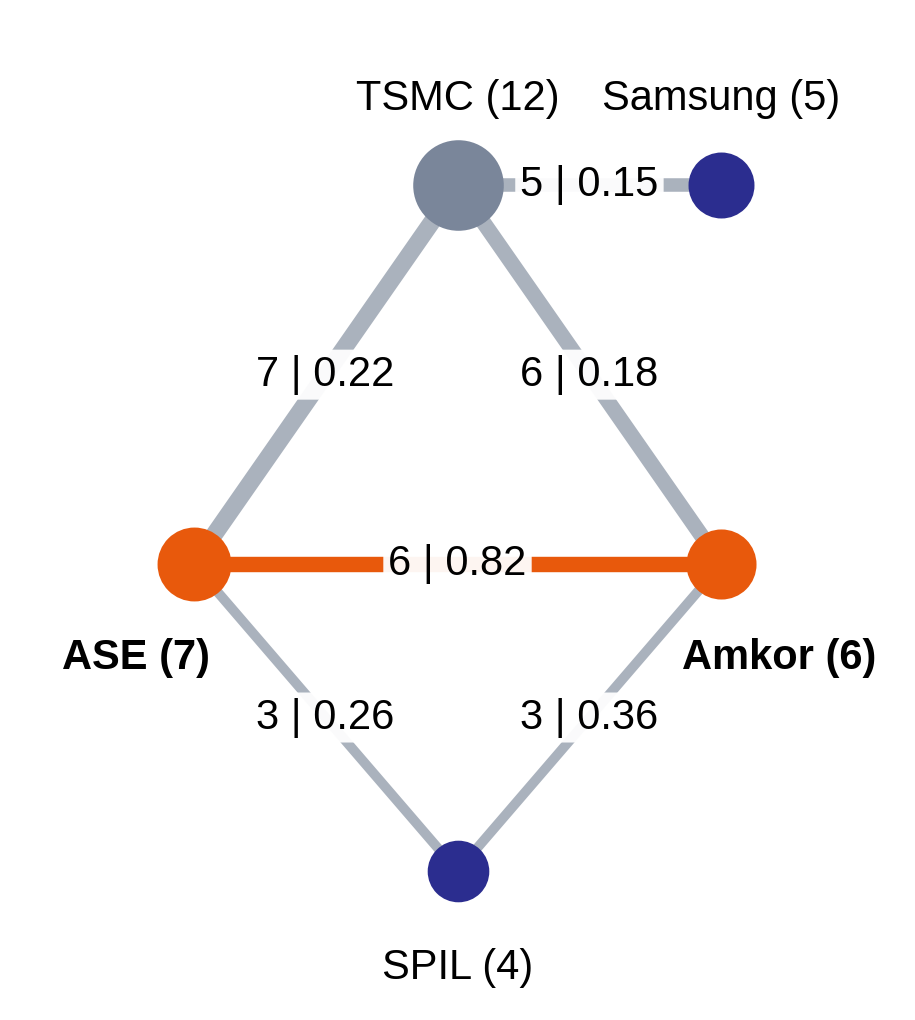

figure for the prior-year 10-Ks; not drawn, named by 2+ filers: Foxconn (3), SMIC (3), UMC (2), GlobalFoundries (2)


In [36]:
from matplotlib import font_manager as fm
plt.rcParams["font.family"] = [f for f in ("Liberation Sans", "Arial", "DejaVu Sans") if f in {x.name for x in fm.fontManager.ttflist}][0]

YEAR_TXT = "latest 10-Ks" if BACK == 0 else "prior-year 10-Ks"
deg_s = supplier_degree.set_index("supplier")["filers_depending"]
deps_p = E.groupby("supplier")["ticker"].apply(set)

PAGE_POS = {"TSMC": (1.0, 1.45), "Samsung": (2.0, 1.45), "ASE": (0.0, 0.4), "Amkor": (2.0, 0.4), "SPIL": (1.0, -0.45)}
PAGE_EDGES = [("ASE", "Amkor"), ("TSMC", "ASE"), ("TSMC", "Amkor"), ("TSMC", "Samsung"), ("ASE", "SPIL"), ("Amkor", "SPIL")]
HOT = {"ASE", "Amkor"}
absent = [n for n in PAGE_POS if n not in deps_p.index]
if absent:
    print(f"WARNING: these suppliers have no supply edge in this run and are left out of the figure: {absent}")
pos_p = {n: p for n, p in PAGE_POS.items() if n in deps_p.index}
edges_p = [(a, b) for a, b in PAGE_EDGES if a in pos_p and b in pos_p]

def pair_stats(a, b):
    """shared filers and NPMI (the primary weight); Jaccard is in the tables."""
    A, B = deps_p[a], deps_p[b]
    n = E["ticker"].nunique()
    p_a, p_b, p_ab = len(A) / n, len(B) / n, len(A & B) / n
    return len(A & B), (1.0 if p_ab >= 1 else math.log(p_ab / (p_a * p_b)) / (-math.log(p_ab)))

fig, ax = plt.subplots(figsize=(2.85, 3.2), dpi=300)
for a, b in edges_p:
    sh, jc = pair_stats(a, b)
    ax.plot([pos_p[a][0], pos_p[b][0]], [pos_p[a][1], pos_p[b][1]],
            color="#e8590c" if {a, b} == HOT else "#aab2bd", lw=1.0 + 0.45 * sh, zorder=1, solid_capstyle="round")
for a, b in edges_p:
    sh, jc = pair_stats(a, b)
    ax.text((pos_p[a][0] + pos_p[b][0]) / 2, (pos_p[a][1] + pos_p[b][1]) / 2, f"{sh} | {jc:.2f}",
            ha="center", va="center", fontsize=10, zorder=3, bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.95))
for n, (x, y) in pos_p.items():
    k = len(deps_p[n])
    ax.scatter(x, y, s=70 + 30 * k, color="#e8590c" if n in HOT else ("#7a869a" if n in HUBS else "#2b2d8f"), zorder=4)
    dx = {"ASE": -0.22, "Amkor": 0.22}.get(n, 0.0)
    dy = {"SPIL": -0.27, "ASE": -0.26, "Amkor": -0.26}.get(n, 0.24)
    ax.text(x + dx, y + dy, f"{n} ({k})", ha="center", va="center", fontsize=10,
            fontweight="bold" if n in HOT else "normal", zorder=5)
ax.set_xlim(-0.62, 2.62); ax.set_ylim(-0.78, 1.88); ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
fig.savefig(f"page_figure{SUFFIX}.png", dpi=300)
plt.show()

not_drawn = [(s_, int(n_)) for s_, n_ in deg_s.items() if n_ >= 2 and s_ not in pos_p]
print(f"figure for the {YEAR_TXT}; not drawn, named by 2+ filers:", ", ".join(f"{s_} ({n_})" for s_, n_ in not_drawn) or "none")

## 9. Numbers for the one-page report

In [37]:
print("DATA section")
print("  source      : SEC EDGAR, latest 10-K per filer (submissions API), public data" if BACK == 0 else "  source      : SEC EDGAR, previous-year 10-K per filer")
_rd = meta.loc[meta["report_date"].astype(str) != "", "report_date"]
print(f"  period      : fiscal years ended {_rd.min()} to {_rd.max()} (filers with a pinned filing)")
if SOURCE == "live":
    print(f"  volume      : {len(meta)} filings, {int(scope['n_in_scope'].sum())} in-scope paragraphs, {len(sup_rows)} supplier-mention sentences")
    print(f"  section fallback used for: {scope.loc[~scope['section_found'], 'ticker'].tolist()}")
else:
    print(f"  volume      : {len(_rd)} pinned filings, {len(sup_rows)} supplier-mention sentences (embedded table)")
print("GRAPH section")
print(f"  nodes: {B.number_of_nodes()} ({E['ticker'].nunique()} filers + {E['supplier'].nunique()} suppliers) | edges: {B.number_of_edges()}")
print(f"  filers with no supply edge: {sorted(set(meta['ticker']) - set(E['ticker']))}")
print("  top overlapping supplier pairs (shared filers | jaccard | npmi; ranked by shared, see core pairs for NPMI order):")
print(OV.head(5).to_string(index=False))
print("  hubs:", HUBS, "| core pairs (no hubs, shared >= 2):")
print(OV_core.to_string(index=False))

DATA section
  source      : SEC EDGAR, previous-year 10-K per filer
  period      : fiscal years ended 2024-08-29 to 2025-06-30 (filers with a pinned filing)
  volume      : 21 pinned filings, 170 supplier-mention sentences (embedded table)
GRAPH section
  nodes: 28 (14 filers + 14 suppliers) | edges: 49
  filers with no supply edge: ['AMZN', 'DELL', 'GOOGL', 'META', 'MPWR', 'MRVL', 'MSFT', 'MU', 'ON', 'QRVO', 'SMCI', 'SWKS', 'SYNA']
  top overlapping supplier pairs (shared filers | jaccard | npmi; ranked by shared, see core pairs for NPMI order):
      a     b  shared  jaccard  npmi  dep_a  dep_b
    ASE  TSMC       7    0.583 0.222      7     12
    ASE Amkor       6    0.857 0.818      7      6
  Amkor  TSMC       6    0.500 0.182      6     12
Samsung  TSMC       5    0.417 0.150      5     12
   SPIL  TSMC       4    0.333 0.123      4     12
  hubs: ['TSMC'] | core pairs (no hubs, shared >= 2):
              a       b  shared  jaccard   npmi  dep_a  dep_b
            ASE   Amkor

## 10. Check against the reported results

In [38]:
EXPECTED = {'0': {'filers_with_edge': 14, 'edges': 49, 'hubs': ['TSMC'], 'top_core_pair': 'ASE-Amkor', 'ase_amkor_shared': 6, 'ase_amkor_jaccard': 0.86, 'ase_amkor_npmi': 0.82, 'npmi_first_configs': 8, 'n_npmi_configs': 8, 'ase_amkor_top3_configs': 22, 'n_configs': 24, 'edges_any_mention': 65, 'top_pair_any_mention': 'ASE-Amkor', 'n_uncertain_rows': 10, 'flip_top_pair_same': True, 'core_pair_edges': 12, 'core_pair_sentences': 20}, '1': {'filers_with_edge': 14, 'edges': 49, 'hubs': ['TSMC'], 'top_core_pair': 'ASE-Amkor', 'ase_amkor_shared': 6, 'ase_amkor_jaccard': 0.86, 'ase_amkor_npmi': 0.82, 'npmi_first_configs': 8, 'n_npmi_configs': 8, 'ase_amkor_top3_configs': 22, 'n_configs': 24, 'edges_any_mention': 66, 'top_pair_any_mention': 'ASE-Amkor', 'n_uncertain_rows': 8, 'flip_top_pair_same': True, 'core_pair_edges': 12, 'core_pair_sentences': 21}}
exp = EXPECTED[str(BACK)]
OVc = OV_core.iloc[0]
ac = OV[(OV["a"] == "ASE") & (OV["b"] == "Amkor")].iloc[0]
st_ = stab.set_index("pair")
got = dict(filers_with_edge=int(E["ticker"].nunique()), edges=int(len(E)), hubs=list(HUBS),
           top_core_pair=f"{OVc['a']}-{OVc['b']}", ase_amkor_shared=int(ac["shared"]), ase_amkor_jaccard=round(float(ac["jaccard"]), 2), ase_amkor_npmi=round(float(ac["npmi"]), 2),
           npmi_first_configs=int(NPMI_FIRST.get("ASE-Amkor", 0)), n_npmi_configs=N_NPMI_CFG,
           edges_any_mention=int(EDGES_ANY), top_pair_any_mention=TOP_ANY, n_uncertain_rows=int(N_UNSURE), flip_top_pair_same=bool(FLIP_SAME),
           core_pair_edges=int(CORE_EDGES), core_pair_sentences=int(CORE_SENTENCES),
           ase_amkor_top3_configs=int(st_.loc["ASE-Amkor", "in_top3"]) if "ASE-Amkor" in st_.index else 0, n_configs=int(len(sweep)))
rows = [(k, exp[k], got[k], "ok" if exp[k] == got[k] else "DIFFERENT") for k in exp]
report = pd.DataFrame(rows, columns=["quantity", "reported", "this run", "status"])
display(report)
if (report["status"] == "ok").all():
    print("All reported results reproduced.")
else:
    print("Some results differ. Likely causes: labels_v3.csv changed or missing (see step 5), filings not pinned (see the '[not pinned]' lines in step 2),")
    print("or the filer list / supplier dictionary in cell 1 was edited.")

,quantity,reported,this run,status
0,filers_with_edge,14,14,ok
1,edges,49,49,ok
2,hubs,[TSMC],[TSMC],ok
3,top_core_pair,ASE-Amkor,ASE-Amkor,ok
4,ase_amkor_shared,6,6,ok
5,ase_amkor_jaccard,0.86,0.86,ok
6,ase_amkor_npmi,0.82,0.82,ok
7,npmi_first_configs,8,8,ok
8,n_npmi_configs,8,8,ok
9,ase_amkor_top3_configs,22,22,ok


All reported results reproduced.
